# Experiment 1 on real data: BOSCH plasma etching

Same question as Experiment 1 in `Process_Study_Code_Only.ipynb`: which surrogate predicts held-out output maps best, and does the PCA step help?
Here the output map is large, as in the synthetic study: 89 measurement points × 2 channels (oxide etch and Si etch depth, µm) = 178 values per wafer.

Differences from the synthetic study: 88 real wafers in 10 lots (data from Zenodo, see `data/bosch/SOURCE.md`);
6 inputs describing each wafer (position in its lot, lot conditioning, incoming oxide thickness);
**leave-one-lot-out** testing (train on 9 lots, predict every wafer of the 10th);
training sizes 20, 40, 78; and RMSE against *measured* (not clean) maps.

The notebook runs the whole pipeline from the original files, top to bottom:

1. **Data ingestion** — download the dataset files from Zenodo (about 7.4 GB, skipped when valid copies exist), check their checksums, and build the lot table, the machine-reading features and the emission-line features.
2. **Model tables** — the input table (6 values per wafer), the target table (178 values per wafer) and the train/test split table that every experiment below uses.
3. **Experiment 1** — seven models, leave-one-lot-out, with the 6 inputs.
4. **Extra inputs** — the same test with machine readings or plasma light added, plus a PCA model with one shared GP.

In [1]:
from pathlib import Path
import hashlib
import re
import urllib.request
import zipfile
import xml.etree.ElementTree as ET
from time import perf_counter
import sys
import warnings
import numpy as np
import pandas as pd
import h5py
import scipy
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display

thread_limit = threadpool_limits(limits=1)
DATA = Path("data/bosch")            # small original files and the derived tables
RAW = DATA / "raw"                    # large original files (git-ignored)
OUT = Path("results/bosch")
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
versions = {"python": sys.version.split()[0], "numpy": np.__version__,
            "scipy": scipy.__version__, "pandas": pd.__version__,
            "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__,
            "h5py": h5py.__version__}
print(versions)
warning_log = []

def fit_recorded(model, X, y, label):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(X, y)
    for item in caught:
        warning_log.append({"fit": label, "type": item.category.__name__,
                            "message": str(item.message)})
    return model

def save_plot(name):
    plt.savefig(OUT / name, dpi=170, bbox_inches="tight")
    plt.show()


{'python': '3.13.12', 'numpy': '2.5.3', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'h5py': '3.16.0'}


## 1. Data ingestion

All inputs come from one Zenodo record: Sayyed et al., *A Multi-Model Dataset for BOSCH Plasma-Etching*, 2025, https://doi.org/10.5281/zenodo.17122442 (CC BY 4.0; full citation in `data/bosch/SOURCE.md`).

| File | Size | Used for |
| --- | --- | --- |
| `Si_Oxide_etch_89_points.csv` | 0.6 MB | targets (oxide and Si etch at 89 points) and incoming oxide |
| `Lot_status.xlsx` | 12 kB | date and conditioning of each lot |
| `Process_data.nc`, `Dictionary_process.nc` | 9 MB | machine log (31 readings, 5 per second) |
| `Day_YYYY_MM_DD.nc` × 10, `Dictionary_OES.nc` | 7.4 GB | plasma light spectra (3,648 wavelengths, about 24 per second) |

The two small files are kept in `data/bosch/`; the large ones go to `data/bosch/raw/`, which git ignores. Each file is downloaded only if it is missing or its MD5 checksum does not match the value published on Zenodo. The first run therefore downloads about 7.4 GB; later runs only re-check the checksums.

From these files this section builds three tables, written to `data/bosch/` so they can be inspected (git ignores them; every run rebuilds them):

- `lot_status.csv` — lot number, date and conditioning label, read from `Lot_status.xlsx`.
- `process_features.csv` — each machine reading averaged over the etch steps and over the protective steps.
- `oes_lines.csv` — heights of the emission lines that form clear peaks in the plasma spectra.

No etch measurement is used to build the machine-reading or emission-line features.

In [2]:
# Download every file of the Zenodo record that the notebook uses, and check it against the published MD5.
ZENODO = "https://zenodo.org/records/17122442/files/{name}?download=1"
MANIFEST = {   # file name: (MD5 published on Zenodo, folder)
    "Si_Oxide_etch_89_points.csv": ("446e75b040eea37b634eeb8f763a62fc", DATA),
    "Lot_status.xlsx": ("339beca13f321dc3af244bf2d2ce284c", DATA),
    "Process_data.nc": ("4567d24ec2125102a2e5129203ba31fa", RAW),
    "Dictionary_process.nc": ("0dde5a3a913eb1fa8512ef2f8748fb34", RAW),
    "Dictionary_OES.nc": ("e7979670371604ff6f46d75dc3221cb0", RAW),
    "Day_2024_07_02.nc": ("28f96ab71714e070af1b2ccddb952b60", RAW),
    "Day_2024_07_05.nc": ("fe2a0432b433daf0bdf9745b877b879b", RAW),
    "Day_2024_07_09.nc": ("1632b5b67f52cc8e8a53191777a330b7", RAW),
    "Day_2024_07_11.nc": ("a32f4406f243d267a430fc9a3624ee28", RAW),
    "Day_2024_07_19.nc": ("dd631872ca55ca28965e464fe81f13f2", RAW),
    "Day_2024_08_01.nc": ("3a2f4efc1ee23fb09dbe1b920c1913ae", RAW),
    "Day_2024_08_05.nc": ("4d13022c1817334dd02ffdfa936c4469", RAW),
    "Day_2024_08_07.nc": ("a9e989c84ba2c29aecc6de7f3410f60c", RAW),
    "Day_2024_08_21.nc": ("aeee1ee145575633b599a71c2622bb3a", RAW),
    "Day_2024_08_22.nc": ("e63c41f3560914e9a1fa9c388314b3a5", RAW),
}

def md5_of(path):
    digest = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()

def fetch(name, md5, folder, attempts=3):
    """Download one file unless a copy with the right checksum is already there."""
    target = folder / name
    if target.exists() and md5_of(target) == md5:
        return "present"
    folder.mkdir(parents=True, exist_ok=True)
    partial = target.with_name(target.name + ".part")
    for attempt in range(1, attempts + 1):
        urllib.request.urlretrieve(ZENODO.format(name=name), partial)
        if md5_of(partial) == md5:
            partial.replace(target)
            return "downloaded"
        print(f"  {name}: checksum mismatch on attempt {attempt}, retrying", flush=True)
    raise RuntimeError(f"{name}: checksum still wrong after {attempts} downloads")

started = perf_counter()
for name, (md5, folder) in MANIFEST.items():
    status = fetch(name, md5, folder)
    print(f"{status:10s} {folder / name}  ({(folder / name).stat().st_size / 1e6:,.1f} MB)", flush=True)
print(f"All {len(MANIFEST)} files present with the published checksums ({perf_counter() - started:.0f} s).")

present    data/bosch/Si_Oxide_etch_89_points.csv  (0.6 MB)


present    data/bosch/Lot_status.xlsx  (0.0 MB)


present    data/bosch/raw/Process_data.nc  (8.8 MB)


present    data/bosch/raw/Dictionary_process.nc  (0.1 MB)


present    data/bosch/raw/Dictionary_OES.nc  (0.1 MB)


present    data/bosch/raw/Day_2024_07_02.nc  (829.4 MB)


... (6 outputs left out)

present    data/bosch/raw/Day_2024_08_07.nc  (823.3 MB)


present    data/bosch/raw/Day_2024_08_21.nc  (816.3 MB)


present    data/bosch/raw/Day_2024_08_22.nc  (818.0 MB)


All 15 files present with the published checksums (12 s).


In [3]:
# Lot table: read the first sheet of Lot_status.xlsx (an .xlsx file is a zip of XML files, so no Excel
# reader is needed). Its first table has one row per lot: "Lot N", the date as text, and the conditioning type.
def read_xlsx_rows(path):
    ns = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with zipfile.ZipFile(path) as z:
        shared = [ "".join(t.text or "" for t in si.iter(f"{{{ns['m']}}}t"))
                   for si in ET.fromstring(z.read("xl/sharedStrings.xml")).findall("m:si", ns)]
        sheet = ET.fromstring(z.read("xl/worksheets/sheet1.xml"))
    rows = []
    for row in sheet.find("m:sheetData", ns).findall("m:row", ns):
        cells = {}
        for c in row.findall("m:c", ns):
            value = c.find("m:v", ns)
            if value is not None:
                column = re.match(r"[A-Z]+", c.get("r")).group()
                cells[column] = shared[int(value.text)] if c.get("t") == "s" else value.text
        rows.append(cells)
    return rows

def parse_date(text):
    """'2th July 2024', '21st Aug 2024' -> '2024-07-02', '2024-08-21'."""
    day, month, year = re.match(r"\s*(\d+)\w*\s+([A-Za-z]+)\s+(\d{4})", text).groups()
    return pd.Timestamp(f"{day} {month[:3]} {year}").strftime("%Y-%m-%d")

lot_rows = [r for r in read_xlsx_rows(DATA / "Lot_status.xlsx") if re.fullmatch(r"Lot \d+", r.get("A", "").strip()) and "E" in r]
lots = pd.DataFrame({"lot": [int(r["A"].split()[1]) for r in lot_rows],
                     "date": [parse_date(r["B"]) for r in lot_rows],
                     "conditioning": [r["E"].strip() for r in lot_rows]}).sort_values("lot", ignore_index=True)
assert lots.lot.tolist() == list(range(1, 11)) and lots.date.is_monotonic_increasing
lots.to_csv(DATA / "lot_status.csv", index=False)
display(lots)

,lot,date,conditioning
0,1,2024-07-02,3C
1,2,2024-07-05,1C
2,3,2024-07-09,9C
3,4,2024-07-11,3C - Si
4,5,2024-07-19,1C - Si
5,6,2024-08-01,9C - Si
6,7,2024-08-05,3C - SiO2
7,8,2024-08-07,3C - SiO2
8,9,2024-08-21,3C
9,10,2024-08-22,3C - SiO2


In [4]:
# Machine-reading features: for each wafer, find when the plasma is on and which samples belong to the etch step
# (SF6 flow above 500) or the protective step (C4F8 flow above 250), then average every reading over each step.
PROCESS_HZ = 5                                              # machine log: 5 samples per second

def process_features(raw_dir):
    log = h5py.File(raw_dir / "Process_data.nc", "r")
    dec = h5py.File(raw_dir / "Dictionary_process.nc", "r")["data"][:]   # values are stored as codes into this table
    rows, featsets = [], []
    for name in log:                                                       # e.g. Day_2024_07_02_Wafer_01
        g = log[name]
        feats = [x.decode().replace("Stat3_Etch_MV_", "") for x in g["feature"][:]]
        v = pd.DataFrame(dec[g["data"][:]], columns=feats)
        featsets.append(set(feats))
        on = v.SourceRFLoadPower > 0.5 * v.SourceRFLoadPower.max()          # plasma on
        etch, prot = on & (v.Gas5Flow > 500), on & (v.Gas4Flow > 250)       # SF6 etch step / C4F8 protective step
        r = {"key": name[4:14].replace("_", "-") + "_" + name[-2:],
             "etch_time_s": etch.sum() / PROCESS_HZ, "prot_time_s": prot.sum() / PROCESS_HZ,
             "plasma_time_s": on.sum() / PROCESS_HZ}
        for c in feats:
            r[f"{c}|etch"] = v.loc[etch, c].mean()
            r[f"{c}|prot"] = v.loc[prot, c].mean()
        rows.append(r)
    d = pd.DataFrame(rows)
    common = set.intersection(*featsets)                                   # readings recorded for every wafer
    keep = ["key", "etch_time_s", "prot_time_s", "plasma_time_s"] + [
        c for c in d.columns if "|" in c and c.split("|")[0] in common]
    d = d[keep]
    num = d.drop(columns="key")
    varying = num.columns[(num.std() > 1e-9 * (num.abs().mean() + 1e-12)) & num.notna().all()]
    return d[["key"] + list(varying)], sorted(common)

started = perf_counter()
process_table, machine_readings = process_features(RAW)
process_table.to_csv(DATA / "process_features.csv", index=False)
print(f"{len(machine_readings)} readings recorded for every wafer; {process_table.shape[1] - 1} step averages "
      f"differ between wafers; {len(process_table)} wafers in the log ({perf_counter() - started:.0f} s)")
display(process_table.set_index("key").iloc[:3, :8].round(3))

31 readings recorded for every wafer; 53 step averages differ between wafers; 96 wafers in the log (1 s)


,etch_time_s,prot_time_s,plasma_time_s,EpdIntensity|etch,EpdIntensity|prot,ForeLinePressure|etch,ForeLinePressure|prot,Gas1Flow|etch
key,,,,,,,,
2024-07-02_01,429.2,129.0,598.0,0.123,0.123,148.408005,89.213997,0.223
2024-07-02_02,426.6,129.0,595.2,0.123,0.123,147.908005,89.185997,0.231
2024-07-02_03,429.4,129.0,598.2,0.123,0.123,147.785995,89.181999,0.204


In [5]:
# Emission-line features from the plasma spectra.
# 1. Per wafer: find when the plasma is on, split the spectra into the two plasma states (etch / protective) by
#    clustering, and average each state.  2. Correct the wavelength axis with known fluorine lines.
# 3. Keep only the expected lines that form a clear peak; measure each as peak height minus local background.
OES_SECONDS_PER_SPECTRUM = 0.0421                            # about 24 spectra per second

def oes_day(path):
    """Average spectra of one day file: per wafer, over the etch steps and over the protective steps."""
    day = path.name.split("Day_")[1][:10]
    dec = h5py.File(RAW / "Dictionary_OES.nc", "r")["data"][:]
    f = h5py.File(path, "r")
    edges = np.arange(186, 885, 1.0)
    out = {"keys": [], "etch": [], "prot": [], "plasma_s": []}
    for wn in f:
        g = f[wn]
        D = dec[g["data"][:]]                                    # (time, 3648 pixels)
        w = g["wavelengths"][:]
        # Single spectra are noisy, so steps are found on 1 nm bins.
        b = np.digitize(w, edges) - 1
        nb = len(edges) - 1
        ok = (b >= 0) & (b < nb)
        B = np.zeros((len(D), nb), np.float32)
        np.add.at(B.T, b[ok], D[:, ok].T)
        B /= np.maximum(np.bincount(b[ok], minlength=nb), 1)
        # Plasma on: 1 s running mean of the 40 brightest bins, well above the dark level at the start.
        sig = B[:, np.argsort(B.mean(0))[-40:]].mean(1)
        sm = np.convolve(sig, np.ones(24) / 24, "same")
        dark, lit = np.median(sm[:100]), np.percentile(sm, 90)
        on = sm > dark + 0.3 * (lit - dark)
        # Two plasma states: two clusters of brightness-normalised spectra. The etch step is longer
        # (about 4.5 s vs 1.5 s), so the larger cluster is the etch step.
        lab = KMeans(2, n_init=5, random_state=0).fit_predict(
            B[on] / np.maximum(np.abs(B[on]).mean(1, keepdims=True), 1e-6))
        big = np.argmax(np.bincount(lab))
        out["keys"].append(f"{day.replace('_', '-')}_{wn[-2:]}")
        out["etch"].append(D[on][lab == big].mean(0))
        out["prot"].append(D[on][lab != big].mean(0))
        out["plasma_s"].append(on.sum() * OES_SECONDS_PER_SPECTRUM)
    return out, w

# Emission lines to look for (NIST wavelengths, nm). Only those that form a clear peak are kept.
LINES = {"Si288": 288.16, "SiF440": 440.0, "CO483": 483.5, "C2_516": 516.5, "He588": 587.56,
         "H656": 656.28, "F686": 685.60, "F704": 703.75, "Ar750": 750.39, "O777": 777.19}
BANDS = ("C2_516", "CO483")      # molecular band heads: background is taken on the long-wavelength side only
F_LINES = [623.97, 634.85, 641.37, 685.60, 690.25, 703.75, 712.79, 739.87, 775.47]

started = perf_counter()
days = sorted(RAW.glob("Day_2024_*.nc"))
assert len(days) == 10
results = []
for path in days:
    results.append(oes_day(path))
    print(f"{path.name}: {len(results[-1][0]['keys'])} wafers ({perf_counter() - started:.0f} s so far)", flush=True)
w = results[0][1]
assert all(np.allclose(r[1], w) for r in results), "wavelength axis differs between files"
oes_keys = np.concatenate([r[0]["keys"] for r in results])
spec = {"etch": np.vstack([r[0]["etch"] for r in results]), "prot": np.vstack([r[0]["prot"] for r in results])}

# Wavelength calibration: measure the shift on nine known fluorine lines in the average etch spectrum.
M = spec["etch"].mean(0)
found = []
for f_nm in F_LINES:
    win = np.abs(w - (f_nm - 1.2)) <= 0.8
    found.append(w[win][np.argmax(M[win])])
shift = float(np.median(np.array(F_LINES) - np.array(found)))
print(f"Wavelength shift measured on {len(F_LINES)} fluorine lines: {shift:.2f} nm")
w = w + shift

feats, report = {}, []
for phase, A in spec.items():
    M = A.mean(0)
    for name, lam in LINES.items():
        win = np.flatnonzero(np.abs(w - lam) <= 1.0)
        pk = win[np.argmax(M[win])]
        if name in BANDS:
            bg = np.flatnonzero((w - w[pk] > 1.5) & (w - w[pk] <= 6.0))
        else:
            bg = np.flatnonzero((np.abs(w - w[pk]) <= 6.0) & (np.abs(w - w[pk]) > 1.5))
        base = np.median(M[bg])
        ripple = 1.4826 * np.median(np.abs(M[bg] - base))
        height = M[pk] - base
        keep = pk not in (win[0], win[-1]) and height > 5 * ripple   # a real local peak, 5x the background ripple
        report.append({"line": name, "phase": phase, "peak_nm": round(w[pk], 2),
                       "height_over_ripple": round(height / ripple, 1), "kept": keep})
        if keep:   # per wafer: mean of 5 pixels around the peak minus that wafer's local background
            feats[f"{name}|{phase}"] = A[:, pk - 2:pk + 3].mean(1) - np.median(A[:, bg], axis=1)
oes_table = pd.DataFrame(feats, index=oes_keys)
oes_table.index.name = "key"
oes_table.to_csv(DATA / "oes_lines.csv")
plasma_s = pd.Series(np.concatenate([r[0]["plasma_s"] for r in results]), index=oes_keys)
print("Line search (height over background ripple; kept if a real peak above 5):")
display(pd.DataFrame(report).pivot(index="line", columns="phase", values="height_over_ripple"))
print(f"Kept {oes_table.shape[1]} features: {list(oes_table.columns)}")
print(f"Plasma-on time per wafer: median {plasma_s.median():.1f} s, shortest {plasma_s.min():.1f} s "
      f"({plasma_s.idxmin()}; its spectrometer recording is short, the machine log shows a normal run)")
print(f"Spectra processed in {perf_counter() - started:.0f} s")

Day_2024_07_02.nc: 10 wafers (11 s so far)


Day_2024_07_05.nc: 10 wafers (22 s so far)


Day_2024_07_09.nc: 10 wafers (32 s so far)


Day_2024_07_11.nc: 10 wafers (43 s so far)


Day_2024_07_19.nc: 10 wafers (54 s so far)


Day_2024_08_01.nc: 10 wafers (65 s so far)


... (3 outputs left out)

Day_2024_08_22.nc: 10 wafers (102 s so far)


Wavelength shift measured on 9 fluorine lines: 1.21 nm
Line search (height over background ripple; kept if a real peak above 5):


phase,etch,prot
line,,
Ar750,0.400000,0.500000
C2_516,2.000000,136.000000
CO483,1.300000,0.800000
F686,201.699997,110.400002
F704,90.099998,41.000000
H656,1.600000,1.800000
He588,0.400000,1.200000
O777,1.000000,1.000000
Si288,1.000000,0.900000


Kept 5 features: ['F686|etch', 'F704|etch', 'C2_516|prot', 'F686|prot', 'F704|prot']
Plasma-on time per wafer: median 574.6 s, shortest 398.8 s (2024-08-05_06; its spectrometer recording is short, the machine log shows a normal run)
Spectra processed in 102 s


## 2. Model tables: inputs, targets and train/test splits

One row per wafer. **Inputs (6):** position in the lot, log₃ of the conditioning repeats, three yes/no columns for the conditioning surface (chuck, Si, SiO₂), and the wafer's mean incoming oxide thickness. **Targets (178):** oxide etch and Si etch at the 89 measurement points.

The **split table** lists every training and test set used below, so the experiments read their wafers from one place:

- *Leave-one-lot-out* (main test): for each seed and each held-out lot, the test set is every wafer of that lot; the training sets of 20, 40 and 78 wafers are the first 20, 40, 78 wafers of one seeded shuffle of the other 9 lots, so each smaller set is part of the larger one.
- *Random 10-fold* (check): the 88 wafers are shuffled and cut into 10 test folds, ignoring lots; 78 training wafers are drawn from the rest.

It is saved to `results/bosch/train_test_splits.csv` (wafer keys, in the order used for training; git-ignored, rebuilt on every run).

In [6]:
# Load the 89-point measurements (one row per wafer and point); the lot table `lots` comes from section 1.
raw = pd.read_csv(DATA / "Si_Oxide_etch_89_points.csv")
assert not raw[["X", "Y", "preox_thickness", "oxide_etch", "si_etch"]].isna().any().any()

CHANNELS = ["oxide_etch", "si_etch"]
CHANNEL_LABELS = {"oxide_etch": "Oxide etch", "si_etch": "Si etch"}
SHORT_LABELS = {"oxide_etch": "Oxide", "si_etch": "Si"}
wafer_keys = list(dict.fromkeys(raw.experiment_key))          # file order = etch order
assert wafer_keys == sorted(wafer_keys)
groups = [raw[raw.experiment_key == key] for key in wafer_keys]
XY = groups[0][["X", "Y"]].to_numpy() / 1000.0                  # mm from wafer centre
assert all(np.array_equal(g[["X", "Y"]].to_numpy() / 1000.0, XY) for g in groups), "point order differs"
Y_all = np.stack([g[CHANNELS].to_numpy(float) for g in groups])   # (wafers, 89 points, 2 channels)
POINTS = Y_all.shape[1]

wafers = pd.DataFrame({
    "key": wafer_keys,
    "lot": [int(g.lot_number.iloc[0]) for g in groups],
    "position": [int(g.wafer_number.iloc[0]) for g in groups],
    "preox_mean": [g.preox_thickness.mean() for g in groups]})
assert all(g.lot_number.nunique() == 1 and g.wafer_number.nunique() == 1 for g in groups)
wafers = wafers.merge(lots, on="lot", how="left", validate="many_to_one")
assert (wafers.key.str[:10] == wafers.date).all(), "lot table dates do not match the measurement file"

# Conditioning label, e.g. "3C - Si": repeats = 3, surface = Si. A bare "C" means on the chuck.
label = wafers.conditioning.str.replace(" ", "")
wafers["repeats"] = label.str.extract(r"^(\d+)C")[0].astype(int)
wafers["surface"] = label.str.extract(r"^\d+C-?(.*)$")[0].replace("", "chuck")
assert set(wafers.repeats) == {1, 3, 9} and set(wafers.surface) == {"chuck", "Si", "SiO2"}

# The 6 inputs. Repeats go on a log scale (1, 3, 9 -> 0, 1, 2) because they were chosen in steps of 3x.
INPUTS = ["position", "log3_repeats", "on_chuck", "on_Si", "on_SiO2", "incoming_oxide"]
X_all = np.column_stack([
    wafers.position, np.log(wafers.repeats) / np.log(3),
    wafers.surface == "chuck", wafers.surface == "Si", wafers.surface == "SiO2",
    wafers.preox_mean]).astype(float)
LOTS = sorted(wafers.lot.unique())
lot_of = wafers.lot.to_numpy()

# A lot's conditioning type is "repeated" if another lot has the same label; otherwise the model never sees it
# during leave-one-lot-out training for that lot.
label_counts = lots.conditioning.value_counts()
wafers["type_seen_elsewhere"] = wafers.conditioning.map(label_counts) > 1
SEEN_LOTS = sorted(wafers[wafers.type_seen_elsewhere].lot.unique())
UNSEEN_LOTS = sorted(wafers[~wafers.type_seen_elsewhere].lot.unique())

# Fixed per-channel spread of all measured values: used only to put the two channels on one error scale.
CHANNEL_SD = Y_all.reshape(-1, len(CHANNELS)).std(axis=0)
print(f"X {X_all.shape}, Y {Y_all.shape} (wafers, points, channels); inputs: {INPUTS}")
print("Channel SD over all wafers and points (µm):", dict(zip(CHANNELS, CHANNEL_SD.round(4))))
print("Lots whose conditioning type also appears in another lot:", SEEN_LOTS)
print("Lots with a conditioning type found in no other lot:", UNSEEN_LOTS)
per_lot = wafers.assign(oxide_mean=Y_all[:, :, 0].mean(1), si_mean=Y_all[:, :, 1].mean(1)).groupby("lot").agg(
    date=("date", "first"), conditioning=("conditioning", "first"), wafers=("key", "size"),
    incoming_oxide=("preox_mean", "mean"), oxide_etch=("oxide_mean", "mean"), si_etch=("si_mean", "mean"))
display(per_lot.round(4))

# The model tables: one row per wafer.
input_table = pd.DataFrame(X_all, columns=INPUTS, index=pd.Index(wafers.key, name="wafer")).assign(lot=lot_of)
target_table = pd.DataFrame(Y_all.reshape(len(Y_all), -1), index=input_table.index,
                            columns=[f"{c}_p{p + 1}" for p in range(POINTS) for c in CHANNELS])
print(f"Input table {input_table.shape[0]} wafers x {len(INPUTS)} inputs (lot shown for reference, not an input):")
display(input_table.head())
print(f"Target table {target_table.shape[0]} wafers x {target_table.shape[1]} values (first 6 columns shown, µm):")
display(target_table.iloc[:5, :6].round(4))


X (88, 6), Y (88, 89, 2) (wafers, points, channels); inputs: ['position', 'log3_repeats', 'on_chuck', 'on_Si', 'on_SiO2', 'incoming_oxide']
Channel SD over all wafers and points (µm): {'oxide_etch': np.float64(0.0773), 'si_etch': np.float64(3.6097)}
Lots whose conditioning type also appears in another lot: [np.int64(1), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Lots with a conditioning type found in no other lot: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


,date,conditioning,wafers,incoming_oxide,oxide_etch,si_etch
lot,,,,,,
1,2024-07-02,3C,9,0.9996,0.5870,43.6794
2,2024-07-05,1C,10,0.9971,0.5814,43.5308
3,2024-07-09,9C,10,1.0034,0.6769,43.7619
4,2024-07-11,3C - Si,10,1.0029,0.6934,43.7285
5,2024-07-19,1C - Si,10,1.0031,0.6742,43.4811
6,2024-08-01,9C - Si,10,1.0047,0.6631,43.5575
7,2024-08-05,3C - SiO2,6,1.0030,0.6843,43.7191
8,2024-08-07,3C - SiO2,10,1.0025,0.6838,43.6138
9,2024-08-21,3C,9,1.0005,0.6821,43.8073


Input table 88 wafers x 6 inputs (lot shown for reference, not an input):


,position,log3_repeats,on_chuck,on_Si,on_SiO2,incoming_oxide,lot
wafer,,,,,,,
2024-07-02_01,1.0,1.0,1.0,0.0,0.0,1.000713,1
2024-07-02_02,2.0,1.0,1.0,0.0,0.0,1.000548,1
2024-07-02_03,3.0,1.0,1.0,0.0,0.0,1.000293,1
2024-07-02_04,4.0,1.0,1.0,0.0,0.0,0.999865,1
2024-07-02_05,5.0,1.0,1.0,0.0,0.0,0.999662,1


Target table 88 wafers x 178 values (first 6 columns shown, µm):


,oxide_etch_p1,si_etch_p1,oxide_etch_p2,si_etch_p2,oxide_etch_p3,si_etch_p3
wafer,,,,,,
2024-07-02_01,0.4763,52.4631,0.4626,52.0382,0.4785,52.6763
2024-07-02_02,0.4802,51.8557,0.4700,51.6577,0.4844,51.8768
2024-07-02_03,0.4789,51.9022,0.4651,51.8088,0.4775,51.9110
2024-07-02_04,0.4732,51.6734,0.4577,51.5531,0.4751,51.6248
2024-07-02_05,0.4686,51.0118,0.4529,50.9866,0.4702,51.0277


In [7]:
SIZES = [20, 40, 78]            # 78 = smallest leave-one-lot-out training pool (88 wafers minus a 10-wafer lot)
SEEDS = [10, 20, 30, 40, 50]
K = 5
CONFIG_SEED = 3000
MODEL_NAMES = ["PCA+GP", "PCA+RF", "PCA+MLP"]
DIRECT_NAMES = ["Direct GP", "Direct RF", "Direct MLP"]
# Extra comparison: PCA+RF trained on standardised scores (see the synthetic study).
VARIANT_NAMES = ["PCA+RF (std. scores)"]
ALL_MODELS = MODEL_NAMES + DIRECT_NAMES + VARIANT_NAMES
PAIRS = {"GP": ("PCA+GP", "Direct GP"), "RF": ("PCA+RF", "Direct RF"),
         "MLP": ("PCA+MLP", "Direct MLP")}

def new_gp(n_inputs, observation_noise=True):
    kernel = ConstantKernel(1.0, (0.05, 30.0)) * Matern(
        length_scale=np.ones(n_inputs), length_scale_bounds=(0.1, 10.0), nu=2.5)
    if observation_noise:
        kernel += WhiteKernel(0.01, (1e-6, 0.2))
    return GaussianProcessRegressor(kernel=kernel, alpha=1e-8,
                                    normalize_y=True, n_restarts_optimizer=0)

def new_rf(seed):
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=1,
                                 random_state=seed, n_jobs=1)

def new_mlp(seed, alpha=0.1):
    return MLPRegressor(hidden_layer_sizes=(32,), activation="tanh",
        solver="adam", alpha=alpha, learning_rate_init=0.01,
        max_iter=3000, tol=1e-5, n_iter_no_change=30, random_state=seed)

def prepare_data(X_train, Y_train, X_test):
    # Inputs: standardise. Outputs: the same chain as the synthetic study.
    x_scale = StandardScaler().fit(X_train)
    channels = Y_train.shape[-1]
    y_scale = StandardScaler().fit(Y_train.reshape(-1, channels))
    Y_scaled = y_scale.transform(Y_train.reshape(-1, channels)).reshape(len(Y_train), -1)
    pca = PCA(n_components=K, svd_solver="full").fit(Y_scaled)
    Z = pca.transform(Y_scaled)
    z_scale = StandardScaler().fit(Z)
    return x_scale.transform(X_train), x_scale.transform(X_test), z_scale.transform(Z), y_scale, pca, z_scale

def decode(Z_scaled, y_scale, pca, z_scale, channels):
    Z = z_scale.inverse_transform(Z_scaled)
    Y_scaled = pca.inverse_transform(Z).reshape(-1, channels)
    return y_scale.inverse_transform(Y_scaled).reshape(-1, POINTS, channels)

def scale_outputs(Y, y_scale):
    channels = Y.shape[-1]
    return y_scale.transform(Y.reshape(-1, channels)).reshape(len(Y), -1)

def unscale_outputs(Y_scaled, y_scale, channels):
    return y_scale.inverse_transform(Y_scaled.reshape(-1, channels)).reshape(-1, POINTS, channels)

def squared_errors(truth, prediction):
    """Sum of squared errors per channel, so test folds can be pooled before taking the root."""
    return ((truth - prediction)**2).sum(axis=(0, 1))

def pooled_rmse(frame):
    """RMSE over all pooled test values: per channel (µm) and on the shared normalised scale."""
    count = frame.n_values.sum()
    sse = np.array([frame[f"sse_{c}"].sum() for c in CHANNELS])
    out = {f"rmse_{c}": np.sqrt(s / count) for c, s in zip(CHANNELS, sse)}
    out["rmse_norm"] = np.sqrt(np.sum(sse / CHANNEL_SD**2) / (count * len(CHANNELS)))
    return pd.Series(out)


In [8]:
# Train/test split table: every training and test set used by the experiments below.
split_rows = []
for seed in SEEDS:
    # Leave-one-lot-out: test = one whole lot; training = nested prefixes of one seeded shuffle of the other lots.
    for lot in LOTS:
        test_idx = np.flatnonzero(lot_of == lot)
        pool_idx = np.flatnonzero(lot_of != lot)
        order = np.random.default_rng(seed + CONFIG_SEED + 100 * lot).permutation(len(pool_idx))
        for n in SIZES:
            split_rows.append({"split": "lot", "seed": seed, "fold": lot, "n_train": n,
                               "train_idx": pool_idx[order[:n]], "test_idx": test_idx})
    # Random 10-fold check: lots ignored, largest training size only.
    perm = np.random.default_rng(5000 + seed + CONFIG_SEED).permutation(len(X_all))
    for fold, test_idx in enumerate(np.array_split(perm, len(LOTS)), start=1):
        pool_idx = np.setdiff1d(perm, test_idx)
        order = np.random.default_rng(5000 + seed + CONFIG_SEED + 100 * fold).permutation(len(pool_idx))
        split_rows.append({"split": "random", "seed": seed, "fold": fold, "n_train": max(SIZES),
                           "train_idx": pool_idx[order[:max(SIZES)]], "test_idx": test_idx})
splits = pd.DataFrame(split_rows)
splits["n_test"] = splits.test_idx.map(len)

# Checks: no wafer in both sets; leave-one-lot-out never trains on the held-out lot; smaller training sets are
# prefixes of larger ones; each (split, seed, size) tests every wafer exactly once.
assert all(not set(r.train_idx) & set(r.test_idx) for r in splits.itertuples())
lot_splits = splits[splits.split == "lot"]
assert all(set(lot_of[r.train_idx]).isdisjoint({r.fold}) and set(lot_of[r.test_idx]) == {r.fold} for r in lot_splits.itertuples())
for (seed, lot), g in lot_splits.groupby(["seed", "fold"]):
    trains = g.sort_values("n_train").train_idx.tolist()
    assert all(np.array_equal(a, b[:len(a)]) for a, b in zip(trains, trains[1:]))
for _, g in splits.groupby(["split", "seed", "n_train"]):
    assert sorted(np.concatenate(g.test_idx.tolist())) == list(range(len(X_all)))

keys = wafers.key.to_numpy()
splits.assign(train_wafers=splits.train_idx.map(lambda i: " ".join(keys[i])),
              test_wafers=splits.test_idx.map(lambda i: " ".join(keys[i]))).drop(
    columns=["train_idx", "test_idx"]).to_csv(OUT / "train_test_splits.csv", index=False)
print(f"{len(lot_splits)} leave-one-lot-out training sets ({len(SEEDS)} seeds x {len(LOTS)} lots x {len(SIZES)} sizes) "
      f"and {len(splits) - len(lot_splits)} random-split training sets; saved to {OUT / 'train_test_splits.csv'}")
print("Leave-one-lot-out folds (same for every seed and size):")
display(pd.DataFrame({"held-out lot": LOTS,
                      "conditioning": [lots.set_index("lot").conditioning[l] for l in LOTS],
                      "test wafers": [int((lot_of == l).sum()) for l in LOTS],
                      "test positions": [" ".join(map(str, wafers.position[lot_of == l])) for l in LOTS],
                      "wafers available for training": [int((lot_of != l).sum()) for l in LOTS]}).set_index("held-out lot"))
example = lot_splits[(lot_splits.seed == SEEDS[0]) & (lot_splits.fold == LOTS[0])]
print(f"Example: seed {SEEDS[0]}, lot {LOTS[0]} held out — test wafers: {' '.join(keys[example.test_idx.iloc[0]])}")
for r in example.itertuples():
    print(f"  {r.n_train} training wafers, from lots {sorted(set(lot_of[r.train_idx]))}: "
          f"{' '.join(keys[r.train_idx][:6])} ...")

150 leave-one-lot-out training sets (5 seeds x 10 lots x 3 sizes) and 50 random-split training sets; saved to results/bosch/train_test_splits.csv
Leave-one-lot-out folds (same for every seed and size):


,conditioning,test wafers,test positions,wafers available for training
held-out lot,,,,
1,3C,9,1 2 3 4 5 6 8 9 10,79
2,1C,10,1 2 3 4 5 6 7 8 9 10,78
3,9C,10,1 2 3 4 5 6 7 8 9 10,78
4,3C - Si,10,1 2 3 4 5 6 7 8 9 10,78
5,1C - Si,10,1 2 3 4 5 6 7 8 9 10,78
6,9C - Si,10,1 2 3 4 5 6 7 8 9 10,78
7,3C - SiO2,6,1 2 3 4 5 6,82
8,3C - SiO2,10,1 2 3 4 5 6 7 8 9 10,78
9,3C,9,1 2 3 4 5 6 7 8 10,79


Example: seed 10, lot 1 held out — test wafers: 2024-07-02_01 2024-07-02_02 2024-07-02_03 2024-07-02_04 2024-07-02_05 2024-07-02_06 2024-07-02_08 2024-07-02_09 2024-07-02_10
  20 training wafers, from lots [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]: 2024-08-05_06 2024-07-11_09 2024-07-11_06 2024-07-19_04 2024-07-05_02 2024-07-11_07 ...
  40 training wafers, from lots [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]: 2024-08-05_06 2024-07-11_09 2024-07-11_06 2024-07-19_04 2024-07-05_02 2024-07-11_07 ...
  78 training wafers, from lots [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]: 2024-08-05_06 2024-07-11_09 2024-07-11_06 2024-07-19_04 2024-07-05_02 2024-07-11_07 ...


## 3. Experiment 1: leave-one-lot-out with the 6 inputs

In [9]:
def run_one(seed, n, X_train, Y_train, X_test, Y_test, split, fold):
    """Fit every model on one training set and record squared errors on one test fold."""
    channels = Y_train.shape[-1]
    rows, predictions = [], {}
    Xt, Xq, Zt, ys, pca, zs = prepare_data(X_train, Y_train, X_test)
    test_flat = ys.transform(Y_test.reshape(-1, channels)).reshape(len(Y_test), -1)
    Z_test = zs.transform(pca.transform(test_flat))
    base = {"split": split, "seed": seed, "n_train": n, "fold": fold, "n_values": len(Y_test) * POINTS}
    oracle = squared_errors(Y_test, decode(Z_test, ys, pca, zs, channels))
    diagnostic = {**base, "pca_variance": pca.explained_variance_ratio_.sum(),
                  **{f"sse_{c}": s for c, s in zip(CHANNELS, oracle)},
                  "cumulative_variance": np.cumsum(pca.explained_variance_ratio_)}

    def record(name, prediction, fit_seconds, predict_seconds):
        predictions[name] = prediction
        sse = squared_errors(Y_test, prediction)
        rows.append({**base, "model": name, **{f"sse_{c}": s for c, s in zip(CHANNELS, sse)},
                     "fit_seconds": fit_seconds, "predict_seconds": predict_seconds})

    for name in MODEL_NAMES + VARIANT_NAMES:
        label = f"{split}/{fold}/{seed}/{n}/{name}"
        t0 = perf_counter()
        if name == "PCA+GP":
            models = [fit_recorded(new_gp(Xt.shape[1]), Xt, Zt[:, j], label + f"/{j}") for j in range(K)]
        elif name == "PCA+RF":
            # Raw (unstandardised) scores, as in the synthetic study.
            model = fit_recorded(new_rf(seed), Xt, zs.inverse_transform(Zt), label)
        elif name == "PCA+RF (std. scores)":
            model = fit_recorded(new_rf(seed), Xt, Zt, label)
        else:
            model = fit_recorded(new_mlp(seed), Xt, Zt, label)
        fit_seconds = perf_counter() - t0
        t0 = perf_counter()
        if name == "PCA+GP":
            result = [gp.predict(Xq, return_std=True) for gp in models]
            Z_pred = np.column_stack([r[0] for r in result])
            Z_std = np.column_stack([r[1] for r in result])
            diagnostic["latent_hits"] = int((np.abs(Z_test - Z_pred) <= 1.96 * Z_std).sum())
            diagnostic["latent_count"] = Z_test.size
            diagnostic["latent_width_sum"] = float((3.92 * Z_std).sum())
        elif name == "PCA+RF":
            Z_pred = zs.transform(model.predict(Xq))
        else:
            Z_pred = model.predict(Xq)
        prediction = decode(Z_pred, ys, pca, zs, channels)
        record(name, prediction, fit_seconds, perf_counter() - t0)

    # Direct baselines: same inputs and output scaling, no PCA (178 outputs).
    Y_direct = scale_outputs(Y_train, ys)
    for name in DIRECT_NAMES:
        label = f"{split}/{fold}/{seed}/{n}/{name}"
        t0 = perf_counter()
        if name == "Direct GP":
            model = new_gp(Xt.shape[1])           # one shared kernel across all 178 outputs
        elif name == "Direct RF":
            model = new_rf(seed)
        else:
            # Same per-output penalty as PCA+MLP (sklearn sums the L2 penalty, averages the loss).
            model = new_mlp(seed, alpha=0.1 * K / Y_direct.shape[1])
        fit_recorded(model, Xt, Y_direct, label)
        fit_seconds = perf_counter() - t0
        t0 = perf_counter()
        prediction = unscale_outputs(model.predict(Xq), ys, channels)
        record(name, prediction, fit_seconds, perf_counter() - t0)
    return rows, diagnostic, predictions

# Main run: leave one lot out, using the training and test sets of the split table.
rows, diagnostics = [], []
example_predictions = {}          # seed 10, largest size: predictions for every wafer, filled fold by fold
example_variance = None
started = perf_counter()
for seed in SEEDS:
    for split in lot_splits[lot_splits.seed == seed].itertuples():      # from the split table (section 2)
        lot, n, idx, test_idx = split.fold, split.n_train, split.train_idx, split.test_idx
        run_rows, diagnostic, predictions = run_one(
            seed, n, X_all[idx], Y_all[idx], X_all[test_idx], Y_all[test_idx], "lot", lot)
        rows += run_rows
        diagnostics.append(diagnostic)
        if seed == SEEDS[0] and n == max(SIZES):
            for name, p in predictions.items():
                example_predictions.setdefault(name, np.full_like(Y_all, np.nan))[test_idx] = p
            if lot == LOTS[0]:
                example_variance = diagnostic["cumulative_variance"]
    print(f"seed {seed} finished ({perf_counter() - started:.0f} s so far)", flush=True)

fold_results = pd.DataFrame(rows)
diagnostic_table = pd.DataFrame(diagnostics).drop(columns="cumulative_variance")
# Pool the 10 test lots of each (seed, size, model): every wafer is predicted exactly once.
pooled = fold_results.groupby(["seed", "n_train", "model"]).apply(pooled_rmse).reset_index()
summary = pooled.groupby(["n_train", "model"]).agg(
    rmse_norm_mean=("rmse_norm", "mean"), rmse_norm_sd=("rmse_norm", "std"),
    **{f"rmse_{c}_mean": (f"rmse_{c}", "mean") for c in CHANNELS},
    **{f"rmse_{c}_sd": (f"rmse_{c}", "std") for c in CHANNELS}).reset_index()
print(f"Experiment 1 (BOSCH) elapsed: {perf_counter() - started:.1f} seconds")
for metric, label in [("rmse_norm", "Normalised RMSE (both channels; each channel divided by its overall SD)"),
                      ("rmse_oxide_etch", "Oxide etch RMSE (µm)"), ("rmse_si_etch", "Si etch RMSE (µm)")]:
    print(f"{label}: mean over seeds, then sample SD over seeds")
    display(summary.pivot(index="n_train", columns="model", values=metric + "_mean")[ALL_MODELS].round(5))
    display(summary.pivot(index="n_train", columns="model", values=metric + "_sd")[ALL_MODELS].round(5))


seed 10 finished (15 s so far)


seed 20 finished (30 s so far)


seed 30 finished (45 s so far)


seed 40 finished (61 s so far)


seed 50 finished (77 s so far)


Experiment 1 (BOSCH) elapsed: 76.9 seconds
Normalised RMSE (both channels; each channel divided by its overall SD): mean over seeds, then sample SD over seeds


... (4 outputs left out)

model,PCA+GP,PCA+RF,PCA+MLP,Direct GP,Direct RF,Direct MLP,PCA+RF (std. scores)
n_train,,,,,,,
20,0.00466,0.00529,0.00666,0.00466,0.00515,0.01443,0.00453
40,0.00356,0.00228,0.00588,0.00377,0.00209,0.01356,0.00286
78,0.00249,0.00048,0.00912,0.00059,0.00056,0.00646,0.00025


Si etch RMSE (µm): mean over seeds, then sample SD over seeds


model,PCA+GP,PCA+RF,PCA+MLP,Direct GP,Direct RF,Direct MLP,PCA+RF (std. scores)
n_train,,,,,,,
20,0.43606,0.41005,0.45539,0.40109,0.41205,1.19270,0.39915
40,0.44844,0.38503,0.43541,0.37597,0.38729,1.13245,0.37667
78,0.45682,0.38411,0.41909,0.39319,0.38703,1.17497,0.37268


model,PCA+GP,PCA+RF,PCA+MLP,Direct GP,Direct RF,Direct MLP,PCA+RF (std. scores)
n_train,,,,,,,
20,0.03401,0.01534,0.01519,0.02077,0.01396,0.18325,0.02647
40,0.03081,0.00625,0.03369,0.02277,0.02623,0.13202,0.00601
78,0.00280,0.00259,0.01833,0.00057,0.00360,0.12966,0.00241


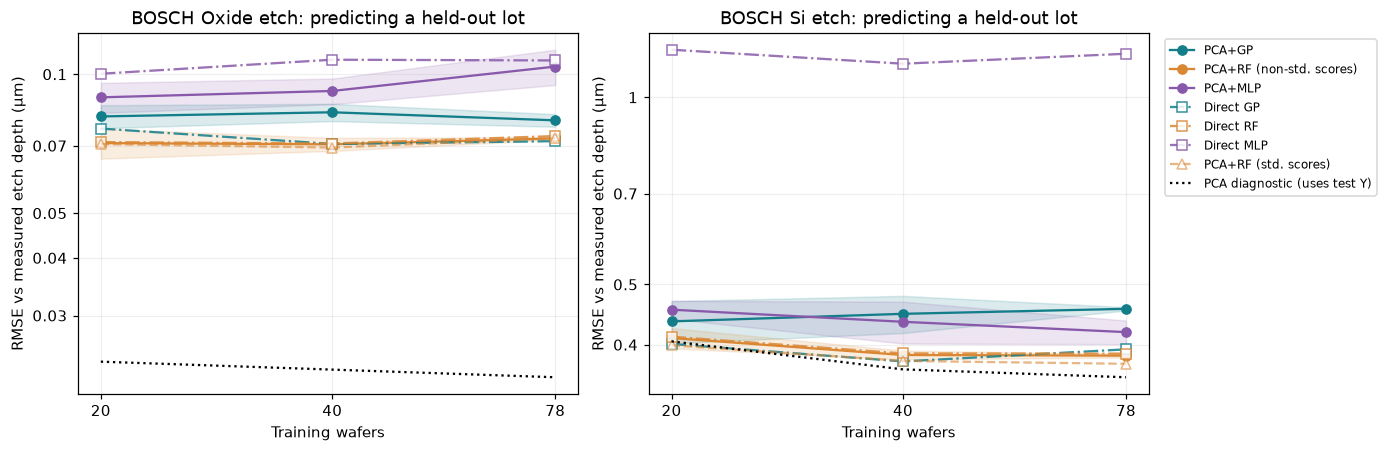

Normalised RMSE by kind of held-out lot (mean over seeds):


model                              PCA+GP   PCA+RF  PCA+MLP  Direct GP  \
group                    n_train                                         
type in no other lot     20       0.67047  0.55544  0.81540    0.69270   
                         40       0.60909  0.50265  0.85559    0.55257   
                         78       0.55797  0.50691  1.00065    0.54016   
type seen in another lot 20       0.82848  0.76011  0.82053    0.71086   
                         40       0.92075  0.80215  0.83147    0.75904   
                         78       0.91188  0.83459  0.88238    0.78952   

model                             Direct RF  Direct MLP  PCA+RF (std. scores)  
group                    n_train                                               
type in no other lot     20         0.56192     0.95587               0.58200  
                         40         0.50532     1.09159               0.50786  
                         78         0.52154     1.08495               0.51000  
type seen in another lot 20         0.76032     0.92843               0.72684  
                         40         0.80487     0.88055               0.77803  
                         78         0.83715     0.89263               0.83227

At 20 training wafers the lowest mean normalised RMSE is PCA+RF (std. scores) (0.65029)
At 40 training wafers the lowest mean normalised RMSE is PCA+RF (std. scores) (0.63871)
At 78 training wafers the lowest mean normalised RMSE is Direct GP (0.65952)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), constrained_layout=True)
colors = {"PCA+GP": "#137e8a", "PCA+RF": "#da8734", "PCA+MLP": "#8859aa",
          "Direct GP": "#137e8a", "Direct RF": "#da8734", "Direct MLP": "#8859aa",
          "PCA+RF (std. scores)": "#da8734"}
legend_names = {"PCA+RF": "PCA+RF (non-std. scores)"}
oracle = diagnostic_table[diagnostic_table.split == "lot"].groupby(["seed", "n_train"]).apply(pooled_rmse).groupby("n_train").mean()
for ax, channel in zip(axes, CHANNELS):
    for name in ALL_MODELS:
        part = summary[summary.model == name]
        x = part.n_train.to_numpy()
        mean, sd = part[f"rmse_{channel}_mean"].to_numpy(), part[f"rmse_{channel}_sd"].to_numpy()
        if name in MODEL_NAMES:
            ax.plot(x, mean, "o-", label=legend_names.get(name, name), color=colors[name])
            ax.fill_between(x, np.maximum(0, mean-sd), mean+sd, alpha=.15, color=colors[name])
        elif name in VARIANT_NAMES:
            ax.plot(x, mean, "^--", label=name, color=colors[name], alpha=.6, markerfacecolor="white")
        else:
            ax.plot(x, mean, "s-.", label=name, color=colors[name], alpha=.85, markerfacecolor="white")
    ax.plot(oracle.index, oracle[f"rmse_{channel}"], ":", color="black", label="PCA diagnostic (uses test Y)")
    ax.set(title=f"BOSCH {CHANNEL_LABELS[channel]}: predicting a held-out lot", xlabel="Training wafers",
           ylabel="RMSE vs measured etch depth (µm)", xscale="log", yscale="log")
    ax.minorticks_off()
    ax.set_xticks(SIZES, labels=SIZES)
    ax.yaxis.set_major_locator(matplotlib.ticker.FixedLocator(
        [0.02, 0.03, 0.04, 0.05, 0.07, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.7, 1, 1.5]))
    ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
    ax.grid(alpha=.2)
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
save_plot("learning_curves.png")

# Same scores split by whether the held-out lot's conditioning type appears in another lot.
groups_rows = []
for group, group_lots in [("type seen in another lot", SEEN_LOTS), ("type in no other lot", UNSEEN_LOTS)]:
    part = fold_results[fold_results.fold.isin(group_lots)]
    g = part.groupby(["seed", "n_train", "model"]).apply(pooled_rmse).reset_index()
    g = g.groupby(["n_train", "model"]).rmse_norm.mean().reset_index().assign(group=group)
    groups_rows.append(g)
by_group = pd.concat(groups_rows).pivot_table(index=["group", "n_train"], columns="model", values="rmse_norm")[ALL_MODELS]
print("Normalised RMSE by kind of held-out lot (mean over seeds):")
display(by_group.round(5))
for n in SIZES:
    row = summary[summary.n_train == n].set_index("model").rmse_norm_mean
    print(f"At {n} training wafers the lowest mean normalised RMSE is {row.idxmin()} ({row.min():.5f})")


In [11]:
# Does PCA help? Pair each PCA model with its direct counterpart on identical training and test wafers.
pooled_wide = pooled.pivot_table(index=["n_train", "seed"], columns="model", values="rmse_norm")
lot_scores = fold_results.groupby(["n_train", "fold", "seed", "model"]).apply(pooled_rmse).reset_index()
lot_wide = lot_scores.groupby(["n_train", "fold", "model"]).rmse_norm.mean().unstack("model")
head = []
for n in SIZES:
    p_all, l_all = pooled_wide.loc[n], lot_wide.loc[n]
    for family, (pca_name, direct_name) in PAIRS.items():
        p, d = p_all[pca_name], p_all[direct_name]
        head.append({"n_train": n, "family": family, "pca_rmse": p.mean(), "direct_rmse": d.mean(),
            "pca_change_pct": 100 * (p.mean() / d.mean() - 1),
            "pca_wins_seeds": f"{int((p < d).sum())}/{len(p)}",
            "pca_wins_lots": f"{int((l_all[pca_name] < l_all[direct_name]).sum())}/{len(l_all)}"})
head_to_head = pd.DataFrame(head)
print("PCA vs direct, normalised RMSE (negative pca_change_pct = PCA version has lower error).")
print("pca_wins_seeds: seeds where PCA wins on all 88 pooled wafers; pca_wins_lots: held-out lots where PCA wins (mean over seeds).")
display(head_to_head.round(5))

std_vs_raw = []
for n in SIZES:
    part = pooled_wide.loc[n]
    raw, std = part["PCA+RF"], part["PCA+RF (std. scores)"]
    std_vs_raw.append({"n_train": n, "raw_scores_rmse": raw.mean(), "std_scores_rmse": std.mean(),
        "direct_rf_rmse": part["Direct RF"].mean(), "std_change_pct": 100 * (std.mean() / raw.mean() - 1),
        "raw_wins": f"{int((raw < std).sum())}/{len(raw)}"})
rf_scaling = pd.DataFrame(std_vs_raw)
print("PCA+RF: raw vs standardised scores (positive std_change_pct = standardising hurts):")
display(rf_scaling.round(5))

fold_results["fit_predict_seconds"] = fold_results.fit_seconds + fold_results.predict_seconds
timing = fold_results.pivot_table(index="n_train", columns="model",
                                  values="fit_predict_seconds", aggfunc="mean")[ALL_MODELS]
print("Mean fit + predict time per fold (seconds):")
display(timing.round(3))

warnings_frame = pd.DataFrame(warning_log, columns=["fit", "type", "message"])
warnings_frame["model"] = warnings_frame.fit.str.split("/").str[4]
warnings_frame["kind"] = np.where(warnings_frame.message.str.contains("close to the specified upper bound"),
    "parameter at upper bound", np.where(warnings_frame.message.str.contains("close to the specified lower bound"),
    "parameter at lower bound", warnings_frame.type))
print("Fit warnings by model and kind:")
display(warnings_frame.groupby(["model", "kind"]).size().rename("count").to_frame())


PCA vs direct, normalised RMSE (negative pca_change_pct = PCA version has lower error).
pca_wins_seeds: seeds where PCA wins on all 88 pooled wafers; pca_wins_lots: held-out lots where PCA wins (mean over seeds).


,n_train,family,pca_rmse,direct_rmse,pca_change_pct,pca_wins_seeds,pca_wins_lots
0,20,GP,0.74601,0.70197,6.27305,0/5,5/10
1,20,RF,0.65370,0.65697,-0.49764,5/5,7/10
2,20,MLP,0.81997,0.94626,-13.34683,5/5,9/10
3,40,GP,0.76168,0.65022,17.14164,0/5,2/10
4,40,RF,0.64921,0.65187,-0.40805,5/5,6/10
5,40,MLP,0.84577,1.00859,-16.14302,4/5,10/10
6,78,GP,0.73223,0.65952,11.02430,0/5,3/10
7,78,RF,0.66842,0.67616,-1.14495,5/5,8/10
8,78,MLP,0.95390,1.00694,-5.26776,3/5,7/10


PCA+RF: raw vs standardised scores (positive std_change_pct = standardising hurts):


,n_train,raw_scores_rmse,std_scores_rmse,direct_rf_rmse,std_change_pct,raw_wins
0,20,0.65370,0.65029,0.65697,-0.52157,1/5
1,40,0.64921,0.63871,0.65187,-1.61634,1/5
2,78,0.66842,0.66851,0.67616,0.01334,3/5


Mean fit + predict time per fold (seconds):


model,PCA+GP,PCA+RF,PCA+MLP,Direct GP,Direct RF,Direct MLP,PCA+RF (std. scores)
n_train,,,,,,,
20,0.048,0.063,0.024,0.023,0.074,0.043,0.064
40,0.076,0.064,0.024,0.058,0.089,0.072,0.064
78,0.149,0.069,0.035,0.210,0.122,0.091,0.069


Fit warnings by model and kind:


count
model     kind                           
Direct GP parameter at lower bound      4
          parameter at upper bound    293
PCA+GP    parameter at lower bound    520
          parameter at upper bound   1326

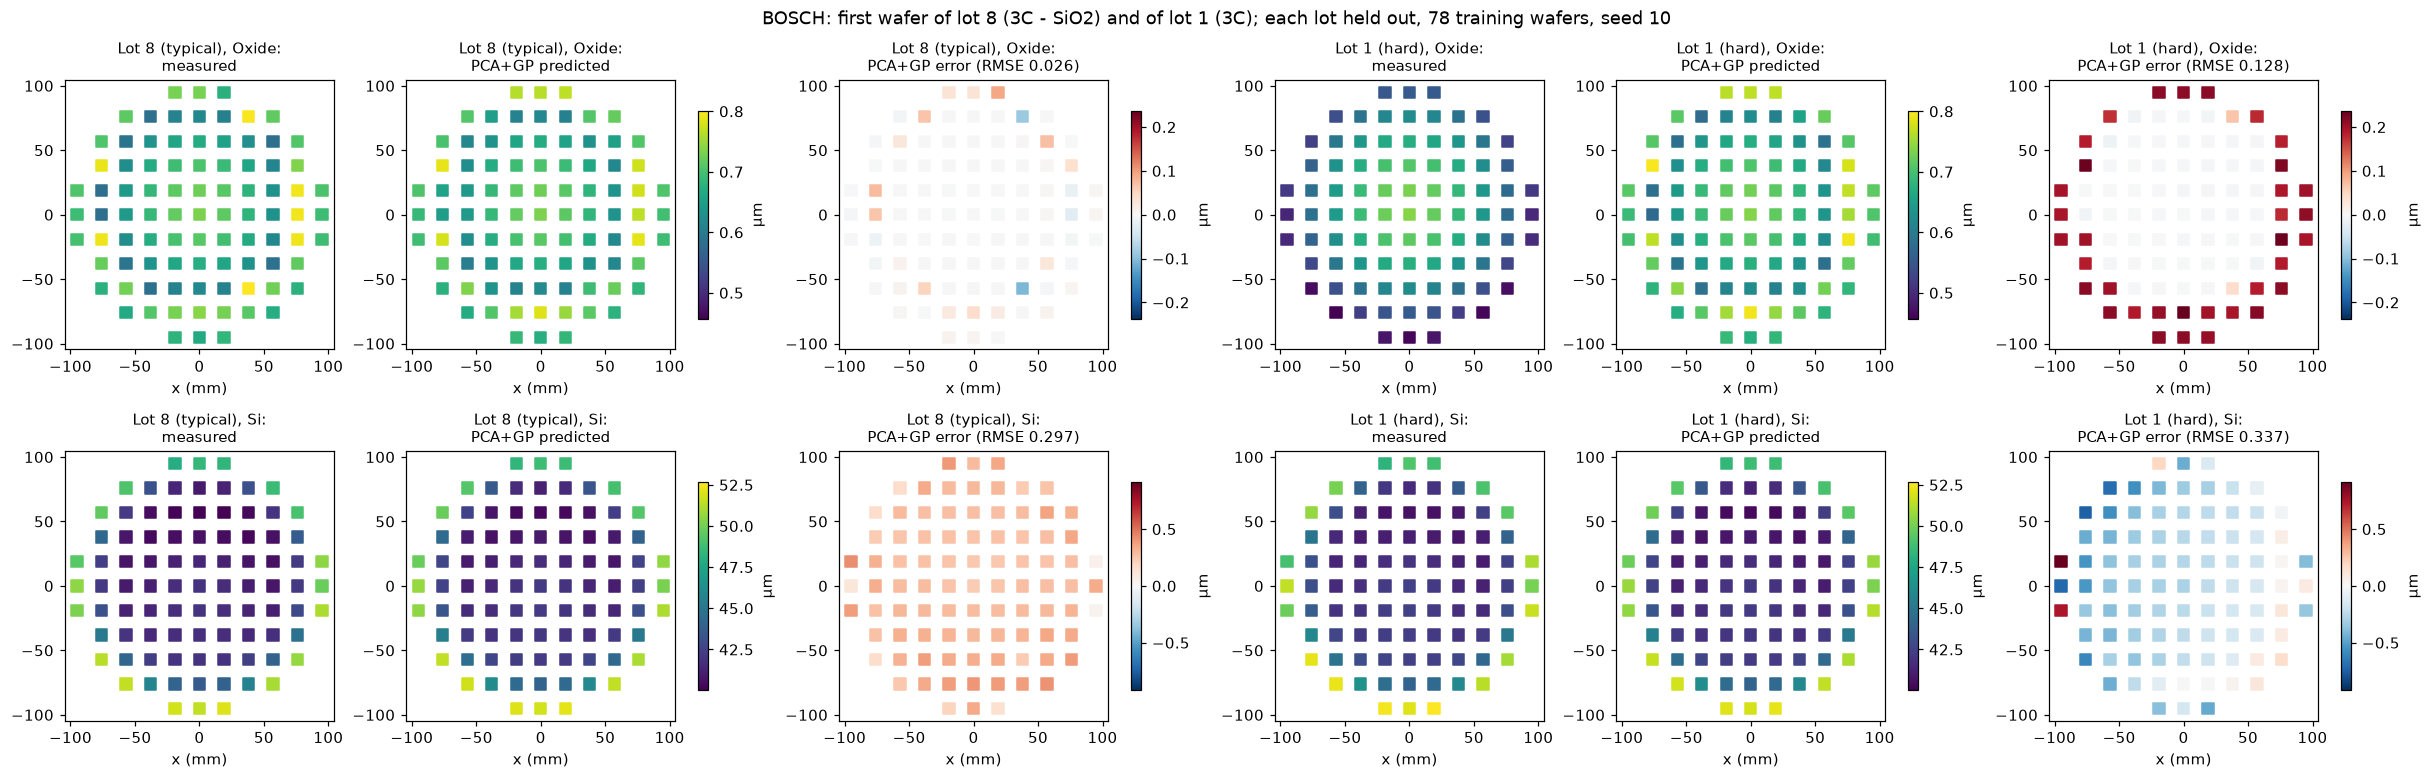

Lot 8 (typical): wafer 2024-08-07_01, measured mean oxide 0.6798 µm, Si 43.744 µm
  PCA+GP                 oxide RMSE 0.0259 µm (mean error +0.0052), Si RMSE 0.2968 µm (mean error +0.289)
  PCA+RF                 oxide RMSE 0.0260 µm (mean error +0.0029), Si RMSE 0.3843 µm (mean error +0.379)
  PCA+MLP                oxide RMSE 0.0409 µm (mean error +0.0245), Si RMSE 0.3577 µm (mean error +0.350)
  Direct GP              oxide RMSE 0.0240 µm (mean error +0.0067), Si RMSE 0.2384 µm (mean error +0.231)
  Direct RF              oxide RMSE 0.0234 µm (mean error +0.0028), Si RMSE 0.3158 µm (mean error +0.308)
  Direct MLP             oxide RMSE 0.0738 µm (mean error +0.0512), Si RMSE 0.3169 µm (mean error +0.269)
  PCA+RF (std. scores)   oxide RMSE 0.0255 µm (mean error +0.0028), Si RMSE 0.3752 µm (mean error +0.370)
Lot 1 (hard): wafer 2024-07-02_01, measured mean oxide 0.6018 µm, Si 44.289 µm
  PCA+GP                 oxide RMSE 0.1278 µm (mean error +0.0792), Si RMSE 0.3367 µm (mean error

In [12]:
# Two held-out wafers on the wafer plane, predicted with their lot held out (seed 10, 78 training wafers):
# a typical one (first wafer of lot 8) and a hard one (first wafer of lot 1, which shares lot 9's 3C conditioning
# but etched about 15% less oxide). Each channel uses one colour scale for both wafers so they can be compared.
EXAMPLES = {"Lot 8 (typical)": 8, "Lot 1 (hard)": 1}
example_rows = {label: int(np.flatnonzero(lot_of == lot)[0]) for label, lot in EXAMPLES.items()}
fig, axes = plt.subplots(2, 6, figsize=(22, 7), constrained_layout=True)
for c, channel in enumerate(CHANNELS):
    rows_here = list(example_rows.values())
    vmin = min(min(Y_all[w, :, c].min(), example_predictions["PCA+GP"][w, :, c].min()) for w in rows_here)
    vmax = max(max(Y_all[w, :, c].max(), example_predictions["PCA+GP"][w, :, c].max()) for w in rows_here)
    limit = max(np.abs(example_predictions["PCA+GP"][w, :, c] - Y_all[w, :, c]).max() for w in rows_here)
    for k, (label, w) in enumerate(example_rows.items()):
        truth, pred = Y_all[w, :, c], example_predictions["PCA+GP"][w, :, c]
        err = pred - truth
        panels = [("measured", truth, "viridis", vmin, vmax), ("PCA+GP predicted", pred, "viridis", vmin, vmax),
                  (f"PCA+GP error (RMSE {np.sqrt((err**2).mean()):.3f})", err, "RdBu_r", -limit, limit)]
        for j, (title, values, cmap_name, lo, hi) in enumerate(panels):
            ax = axes[c, 3*k + j]
            sc = ax.scatter(XY[:, 0], XY[:, 1], c=values, cmap=cmap_name, vmin=lo, vmax=hi, s=55, marker="s")
            ax.set(title=f"{label}, {SHORT_LABELS[channel]}:\n{title}", aspect="equal", xlabel="x (mm)")
            ax.title.set_fontsize(9.5)
            if j in (1, 2):
                fig.colorbar(sc, ax=ax, shrink=.75, label="µm")
fig.suptitle(f"BOSCH: first wafer of lot 8 ({wafers.conditioning[example_rows['Lot 8 (typical)']]}) and of lot 1 "
             f"({wafers.conditioning[example_rows['Lot 1 (hard)']]}); each lot held out, {max(SIZES)} training wafers, "
             f"seed {SEEDS[0]}")
save_plot("example_maps.png")
for label, w in example_rows.items():
    print(f"{label}: wafer {wafers.key[w]}, measured mean oxide {Y_all[w, :, 0].mean():.4f} µm, Si {Y_all[w, :, 1].mean():.3f} µm")
    for name in ALL_MODELS:
        err = example_predictions[name][w] - Y_all[w]
        print(f"  {name:22s} oxide RMSE {np.sqrt((err[:, 0]**2).mean()):.4f} µm (mean error {err[:, 0].mean():+.4f}), "
              f"Si RMSE {np.sqrt((err[:, 1]**2).mean()):.4f} µm (mean error {err[:, 1].mean():+.3f})")


,n_train,pca_variance,oracle_rmse_norm,oracle_rmse_oxide_etch,oracle_rmse_si_etch,latent_95_coverage,latent_95_width
0,20,0.96431,0.23214,0.02383,0.40497,0.78318,2.93438
1,40,0.94904,0.22151,0.02291,0.36506,0.81045,2.90409
2,78,0.94162,0.21331,0.02205,0.35455,0.81500,2.98197


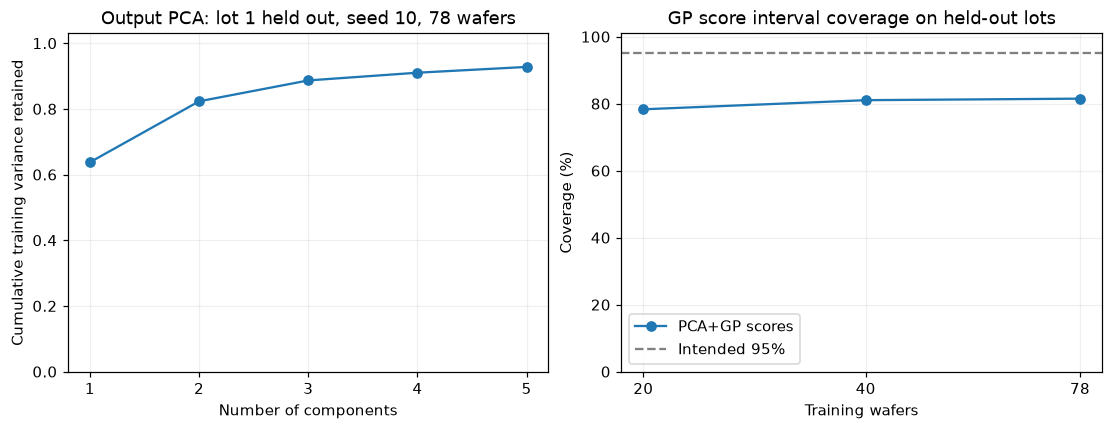

In [13]:
lot_diag = diagnostic_table[diagnostic_table.split == "lot"]
diag_rows = []
for n in SIZES:
    part = lot_diag[lot_diag.n_train == n]
    o = part.groupby("seed").apply(pooled_rmse).mean()
    diag_rows.append({"n_train": n, "pca_variance": part.pca_variance.mean(),
        "oracle_rmse_norm": o.rmse_norm, "oracle_rmse_oxide_etch": o.rmse_oxide_etch, "oracle_rmse_si_etch": o.rmse_si_etch,
        "latent_95_coverage": part.latent_hits.sum() / part.latent_count.sum(),
        "latent_95_width": part.latent_width_sum.sum() / part.latent_count.sum()})
diag_summary = pd.DataFrame(diag_rows)
display(diag_summary.round(5))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].plot(range(1, K+1), example_variance, "o-")
axes[0].set(title=f"Output PCA: lot {LOTS[0]} held out, seed {SEEDS[0]}, {max(SIZES)} wafers",
            xlabel="Number of components", ylabel="Cumulative training variance retained",
            ylim=(0, 1.03), xticks=range(1, K+1))
axes[1].plot(diag_summary.n_train, 100 * diag_summary.latent_95_coverage, "o-", label="PCA+GP scores")
axes[1].axhline(95, color="gray", linestyle="--", label="Intended 95%")
axes[1].set(title="GP score interval coverage on held-out lots", xlabel="Training wafers",
            ylabel="Coverage (%)", ylim=(0, 101), xscale="log")
axes[1].minorticks_off()
axes[1].set_xticks(SIZES, labels=SIZES)
axes[1].legend()
for ax in axes:
    ax.grid(alpha=.2)
save_plot("pca_and_uncertainty.png")


In [14]:
# Extra check: random 10-fold split instead of leave-one-lot-out, at the largest training size.
# Test wafers now come from every lot, so the model has seen other wafers of the same lot.
random_rows = []
started = perf_counter()
n = max(SIZES)
for split in splits[splits.split == "random"].itertuples():          # from the split table (section 2)
    idx, test_idx = split.train_idx, split.test_idx
    run_rows, _, _ = run_one(split.seed, n, X_all[idx], Y_all[idx], X_all[test_idx], Y_all[test_idx], "random", split.fold)
    random_rows += run_rows
print(f"Random-split check elapsed: {perf_counter() - started:.1f} seconds")
random_split = pd.DataFrame(random_rows)
random_pooled = random_split.groupby(["seed", "model"]).apply(pooled_rmse).reset_index()
lot_pooled = pooled[pooled.n_train == n].drop(columns="n_train")
split_compare = pd.concat([lot_pooled.assign(split="lot"), random_pooled.assign(split="random")]).pivot_table(
    index="model", columns="split", values=["rmse_norm", "rmse_oxide_etch", "rmse_si_etch"], aggfunc="mean")
for metric in ["rmse_norm", "rmse_oxide_etch", "rmse_si_etch"]:
    split_compare[(metric, "lot_vs_random_pct")] = 100 * (split_compare[(metric, "lot")] / split_compare[(metric, "random")] - 1)
split_compare = split_compare.reindex(columns=pd.MultiIndex.from_product(
    [["rmse_norm", "rmse_oxide_etch", "rmse_si_etch"], ["lot", "random", "lot_vs_random_pct"]])).loc[ALL_MODELS]
print(f"Mean RMSE at {n} training wafers: held-out lot vs random wafers "
      "(positive lot_vs_random_pct = predicting a new lot is harder):")
display(split_compare.round(5))


Random-split check elapsed: 35.8 seconds
Mean RMSE at 78 training wafers: held-out lot vs random wafers (positive lot_vs_random_pct = predicting a new lot is harder):


rmse_norm                            rmse_oxide_etch  \
                           lot   random lot_vs_random_pct             lot   
model                                                                       
PCA+GP                 0.73223  0.29685         146.66342         0.07945   
PCA+RF                 0.66842  0.40065          66.83215         0.07261   
PCA+MLP                0.95390  0.34854         173.68763         0.10390   
Direct GP              0.65952  0.35616          85.17270         0.07161   
Direct RF              0.67616  0.40117          68.54716         0.07346   
Direct MLP             1.00694  0.32482         209.99620         0.10713   
PCA+RF (std. scores)   0.66851  0.38814          72.23411         0.07265   

                                                rmse_si_etch           \
                       random lot_vs_random_pct          lot   random   
model                                                                   
PCA+GP                0.03164         151.08794      0.45682  0.33657   
PCA+RF                0.04320          68.08631      0.38411  0.33794   
PCA+MLP               0.03742         177.63300      0.41909  0.33411   
Direct GP             0.03827          87.09805      0.39319  0.33435   
Direct RF             0.04319          70.08257      0.38703  0.35628   
Direct MLP            0.03436         211.76067      1.17497  0.41867   
PCA+RF (std. scores)  0.04182          73.73106      0.37268  0.33625   

                                        
                     lot_vs_random_pct  
model                                   
PCA+GP                        35.72911  
PCA+RF                        13.66264  
PCA+MLP                       25.43250  
Direct GP                     17.59642  
Direct RF                      8.63162  
Direct MLP                   180.64719  
PCA+RF (std. scores)          10.83714

In [15]:
# Invariant checks.
assert Y_all.shape == (88, 89, 2) and X_all.shape == (88, len(INPUTS))
assert len(fold_results) == len(SEEDS) * len(LOTS) * len(SIZES) * len(ALL_MODELS)
assert len(random_split) == len(SEEDS) * len(LOTS) * len(ALL_MODELS)
# Every wafer is predicted exactly once per (seed, size, model) in each split.
assert (fold_results.groupby(["seed", "n_train", "model"]).n_values.sum() == len(X_all) * POINTS).all()
assert (random_split.groupby(["seed", "model"]).n_values.sum() == len(X_all) * POINTS).all()
assert all(not np.isnan(p).any() for p in example_predictions.values())
assert min(len(np.flatnonzero(lot_of != lot)) for lot in LOTS) == max(SIZES)
assert (diagnostic_table.pca_variance > 0.5).all()
assert np.isfinite(fold_results[[f"sse_{c}" for c in CHANNELS]]).all().all()
print("All checks passed. Total fit warnings:", len(warning_log))


All checks passed. Total fit warnings: 2640


## 4. Extra inputs: machine readings and plasma light

The six inputs above are known before a lot starts, and four of them are the same for every wafer in a lot. The full dataset also records what happened *during* each etch: 31 machine readings (gas flows, pressures, powers, temperatures; 5 per second) and the plasma's optical emission spectrum (3,648 wavelengths, about 24 spectra per second). This section asks whether they help. It uses the two per-wafer tables built in section 1:

- `process_features.csv`: each machine reading averaged over the etch steps (SF6) and over the protective steps (C4F8), plus the time spent in each — 53 values that differ between wafers.
- `oes_lines.csv`: the height above background of the emission lines that form clear peaks — fluorine at 686 and 704 nm in both steps, and the C2 band at 516 nm in the protective step (5 values). Seven other lines were looked for (Si, SiF, CO, He, H, Ar, O) and are not visible. The spectrometer's wavelength scale reads 1.21 nm low (measured on nine fluorine lines) and is corrected first.

Both are recorded while the wafer is etched, so a model that uses them predicts a wafer's map after etching but before measurement, not before the wafer is run.

Three input sets are compared — the 6 inputs, 6 + 53 machine readings, and 6 + 5 emission lines — with the same lots, sizes, seeds and seven models as above, plus one more model:

- **PCA+shared GP**: one GP, with one kernel and one noise level, predicts all PCA scores together, as Direct GP does for the 178 raw outputs. It uses K = 10 scores, divided by the SD of score 1 and not standardised one by one, so the large scores dominate the kernel fit. PCA+GP above fits a separate GP to each score, and each of them overfits the few training lots.

Before standardising, every input is clipped to its training 0.5–99.5% range, because some machine readings have extreme values. This is done for all three sets, including the 6 inputs, so the 6-input numbers in this section differ slightly from those above for the GP and MLP models.

Two cautions. The shared-GP settings (K = 10, weighting by score size) were picked after trying six versions (scores weighted equally or by size; K = 5, 10, 20) on these same lots. And at 78 training wafers the five seeds use almost the same wafers: the training pools have 78–84 wafers, and for 6 of the 10 lots exactly 78, so those folds are identical for every seed. Agreement across seeds at that size is weak evidence.

Input columns per set: {'6 inputs': 6, '+ 53 machine readings': 59, '+ 5 emission lines': 11}
Machine readings: EpdIntensity, ForeLinePressure, Gas1Flow, Gas2Flow, Gas4Flow, Gas5Flow, Gas7Flow, Heater1Temp, Heater2Temp, Heater3Temp, Heater4Temp, HeliumBPFlow, HeliumBPPressure, PlatenDcBias, PlatenRFLoadCapacitor, PlatenRFLoadPower, PlatenRFPeakToPeak, PlatenRFReflectedPower, PlatenRFTuningCapacitor, Pressure, SourceRF2PeakToPeak, SourceRF2TuningCapacitor, SourceRFLoadPower, SourceRFPeakToPeak, SourceRFReflectedPower, etch_time_s, moriInnerCurrent, plasma_time_s, prot_time_s
Emission-line features (height above local background, counts):


,F686|etch,F704|etch,C2_516|prot,F686|prot,F704|prot
lot,,,,,
1,1021.7,354.8,1011.8,385.7,158.2
2,1003.1,347.9,987.5,378.3,155.0
3,984.5,343.0,977.1,371.6,153.1
4,964.8,333.6,961.8,363.8,149.3
5,946.1,328.7,944.0,357.1,147.4
6,890.1,306.6,883.2,335.2,138.5
7,903.5,313.9,888.6,342.6,142.4
8,913.9,317.0,925.6,345.1,143.6
9,940.1,328.8,970.8,357.8,148.8


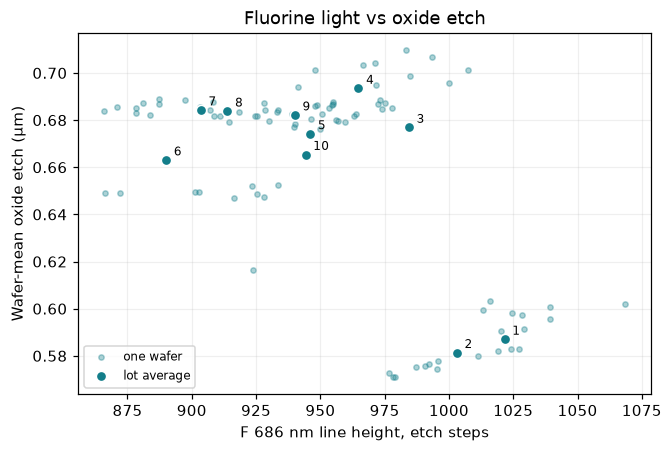

In [16]:
# Per-wafer summaries of the machine log and the plasma light, as written in section 1.
process = pd.read_csv(DATA / "process_features.csv").set_index("key")
oes = pd.read_csv(DATA / "oes_lines.csv").set_index("key")
assert set(wafers.key) <= set(process.index) and set(wafers.key) <= set(oes.index)
assert not process.loc[wafers.key].isna().any().any() and not oes.loc[wafers.key].isna().any().any()
EXTRA_SETS = {
    "6 inputs": X_all,
    "+ 53 machine readings": np.column_stack([X_all, process.loc[wafers.key].to_numpy(float)]),
    "+ 5 emission lines": np.column_stack([X_all, oes.loc[wafers.key].to_numpy(float)]),
}
print("Input columns per set:", {name: X.shape[1] for name, X in EXTRA_SETS.items()})
print("Machine readings:", ", ".join(sorted({c.split("|")[0] for c in process.columns})))
print("Emission-line features (height above local background, counts):")
display(oes.loc[wafers.key].assign(lot=wafers.lot.values).groupby("lot").mean().round(1))

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
f686, oxide_mean = oes.loc[wafers.key, "F686|etch"].to_numpy(), Y_all[:, :, 0].mean(1)
ax.scatter(f686, oxide_mean, s=12, alpha=.35, color="#137e8a", label="one wafer")
for lot in LOTS:
    rows = lot_of == lot
    ax.scatter(f686[rows].mean(), oxide_mean[rows].mean(), s=45, color="#137e8a", edgecolor="white", zorder=3,
               label="lot average" if lot == LOTS[0] else None)
    ax.annotate(str(lot), (f686[rows].mean(), oxide_mean[rows].mean()), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set(title="Fluorine light vs oxide etch", xlabel="F 686 nm line height, etch steps", ylabel="Wafer-mean oxide etch (µm)")
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=.2)
save_plot("plasma_light.png")

In [17]:
K_SHARED = 10
EXTRA_MODELS = ALL_MODELS + ["PCA+shared GP"]

def clip_inputs(X_train, X_test):
    """Clip every input to its training 0.5-99.5 percentile range (bounds from the training wafers only)."""
    lo, hi = np.percentile(X_train, [0.5, 99.5], axis=0)
    return np.clip(X_train, lo, hi), np.clip(X_test, lo, hi)

def shared_gp_prediction(X_train, Y_train, X_test, label):
    """PCA to K_SHARED scores, then ONE GP for all scores (one kernel, one noise level).
    Scores are divided by the SD of score 1 and not standardised one by one, so large scores dominate the fit."""
    channels = Y_train.shape[-1]
    x_scale = StandardScaler().fit(X_train)
    y_scale = StandardScaler().fit(Y_train.reshape(-1, channels))
    Y_scaled = y_scale.transform(Y_train.reshape(-1, channels)).reshape(len(Y_train), -1)
    pca = PCA(n_components=K_SHARED, svd_solver="full").fit(Y_scaled)
    Z = pca.transform(Y_scaled)
    z_unit = Z[:, 0].std()
    gp = new_gp(X_train.shape[1]).set_params(normalize_y=False)
    fit_recorded(gp, x_scale.transform(X_train), Z / z_unit, label)
    Z_pred = gp.predict(x_scale.transform(X_test)) * z_unit
    return y_scale.inverse_transform((Z_pred @ pca.components_ + pca.mean_).reshape(-1, channels)).reshape(-1, POINTS, channels)

# Same training and test sets as the main run (split table), for each input set in turn.
extra_rows = []
EXAMPLE_SET = "+ 5 emission lines"   # predictions kept for every wafer at seed 10, 78 wafers (for the example maps)
extra_example_predictions = {}
started = perf_counter()
for set_name, X_set in EXTRA_SETS.items():
    for split in lot_splits.itertuples():                            # from the split table (section 2)
        seed, lot, n, idx, test_idx = split.seed, split.fold, split.n_train, split.train_idx, split.test_idx
        X_train, X_test = clip_inputs(X_set[idx], X_set[test_idx])
        run_rows, _, predictions = run_one(seed, n, X_train, Y_all[idx], X_test, Y_all[test_idx], "lot", lot)
        t0 = perf_counter()
        prediction = shared_gp_prediction(X_train, Y_all[idx], X_test, f"extra/{set_name}/{lot}/{seed}/{n}/shared")
        sse = squared_errors(Y_all[test_idx], prediction)
        run_rows.append({**{k: run_rows[0][k] for k in ("split", "seed", "n_train", "fold", "n_values")},
                         "model": "PCA+shared GP", **{f"sse_{c}": s for c, s in zip(CHANNELS, sse)},
                         "fit_seconds": perf_counter() - t0, "predict_seconds": np.nan})
        extra_rows += [{**row, "inputs": set_name} for row in run_rows]
        if set_name == EXAMPLE_SET and seed == SEEDS[0] and n == max(SIZES):
            for name, p in {**predictions, "PCA+shared GP": prediction}.items():
                extra_example_predictions.setdefault(name, np.full_like(Y_all, np.nan))[test_idx] = p
    print(f"{set_name}: finished ({perf_counter() - started:.0f} s so far)", flush=True)
extra_results = pd.DataFrame(extra_rows)
extra_pooled = extra_results.groupby(["inputs", "seed", "n_train", "model"]).apply(pooled_rmse).reset_index()
extra_summary = extra_pooled.groupby(["inputs", "n_train", "model"])[["rmse_norm", "rmse_oxide_etch", "rmse_si_etch"]].mean()
SET_NAMES = list(EXTRA_SETS)
for metric, label in [("rmse_norm", "Normalised RMSE"), ("rmse_oxide_etch", "Oxide etch RMSE (µm)"),
                      ("rmse_si_etch", "Si etch RMSE (µm)")]:
    print(f"{label}, 78 training wafers, mean over seeds:")
    display(extra_summary[metric].xs(max(SIZES), level="n_train").unstack("inputs").loc[EXTRA_MODELS, SET_NAMES].round(4))
print("Normalised RMSE by training size, mean over seeds:")
display(extra_summary.rmse_norm.unstack("n_train").unstack("inputs").reorder_levels([1, 0], axis=1)
        .reindex(columns=pd.MultiIndex.from_product([SET_NAMES, SIZES])).loc[EXTRA_MODELS].round(3))

6 inputs: finished (77 s so far)


+ 53 machine readings: finished (428 s so far)


+ 5 emission lines: finished (531 s so far)


Normalised RMSE, 78 training wafers, mean over seeds:


inputs,6 inputs,+ 53 machine readings,+ 5 emission lines
model,,,
PCA+GP,0.7448,0.8211,0.6870
PCA+RF,0.6684,0.7912,0.6452
PCA+MLP,0.9544,0.6762,0.6991
Direct GP,0.6600,0.5954,0.5415
Direct RF,0.6762,0.7882,0.6443
Direct MLP,1.0119,0.7431,0.7460
PCA+RF (std. scores),0.6685,0.7729,0.6331
PCA+shared GP,0.7429,0.7071,0.4865


Oxide etch RMSE (µm), 78 training wafers, mean over seeds:


inputs,6 inputs,+ 53 machine readings,+ 5 emission lines
model,,,
PCA+GP,0.0808,0.0894,0.0746
PCA+RF,0.0726,0.0861,0.0701
PCA+MLP,0.1039,0.0735,0.0760
Direct GP,0.0717,0.0648,0.0587
Direct RF,0.0735,0.0858,0.0700
Direct MLP,0.1076,0.0757,0.0784
PCA+RF (std. scores),0.0726,0.0841,0.0688
PCA+shared GP,0.0807,0.0768,0.0526


Si etch RMSE (µm), 78 training wafers, mean over seeds:


inputs,6 inputs,+ 53 machine readings,+ 5 emission lines
model,,,
PCA+GP,0.4573,0.3979,0.4008
PCA+RF,0.3841,0.3918,0.3857
PCA+MLP,0.4202,0.3533,0.3678
Direct GP,0.3916,0.2978,0.3457
Direct RF,0.3869,0.3732,0.3625
Direct MLP,1.1924,1.3776,1.0556
PCA+RF (std. scores),0.3727,0.3627,0.3673
PCA+shared GP,0.4080,0.3950,0.3555


Normalised RMSE by training size, mean over seeds:


6 inputs               + 53 machine readings         \
                           20     40     78                    20     40   
model                                                                      
PCA+GP                  0.720  0.733  0.745                 0.710  0.676   
PCA+RF                  0.654  0.649  0.668                 0.678  0.751   
PCA+MLP                 0.864  0.860  0.954                 0.721  0.702   
Direct GP               0.701  0.654  0.660                 0.665  0.596   
Direct RF               0.657  0.652  0.676                 0.679  0.748   
Direct MLP              1.005  1.028  1.012                 0.828  0.759   
PCA+RF (std. scores)    0.650  0.639  0.669                 0.663  0.711   
PCA+shared GP           0.708  0.699  0.743                 0.680  0.659   

                            + 5 emission lines                
                         78                 20     40     78  
model                                                         
PCA+GP                0.821              0.663  0.664  0.687  
PCA+RF                0.791              0.614  0.633  0.645  
PCA+MLP               0.676              0.681  0.651  0.699  
Direct GP             0.595              0.618  0.527  0.542  
Direct RF             0.788              0.612  0.632  0.644  
Direct MLP            0.743              0.841  0.754  0.746  
PCA+RF (std. scores)  0.773              0.607  0.592  0.633  
PCA+shared GP         0.707              0.658  0.538  0.486

In [18]:
# Paired comparisons on identical training and test wafers (normalised RMSE).
wide = extra_pooled.pivot_table(index=["n_train", "seed"], columns=["inputs", "model"], values="rmse_norm")
rows = []
for set_name in SET_NAMES[1:]:
    for model in EXTRA_MODELS:
        for n in SIZES:
            new, old = wide.loc[n][(set_name, model)], wide.loc[n][("6 inputs", model)]
            rows.append({"inputs": set_name, "model": model, "n_train": n,
                         "change_%": 100 * (new / old - 1).mean(), "seeds_better": int((new < old).sum())})
vs_base = pd.DataFrame(rows).pivot_table(index=["inputs", "model"], columns="n_train", values=["change_%", "seeds_better"])
print("Each input set against the 6 inputs, same model: mean % change in error, and seeds (of 5) with lower error")
display(vs_base.round(1))

rows = []
for set_name in SET_NAMES:
    for other in ["Direct GP", "PCA+GP"]:
        for n in SIZES:
            shared, ref = wide.loc[n][(set_name, "PCA+shared GP")], wide.loc[n][(set_name, other)]
            rows.append({"inputs": set_name, "against": other, "n_train": n,
                         "change_%": 100 * (shared / ref - 1).mean(), "seeds_better": int((shared < ref).sum())})
print("PCA+shared GP against Direct GP and PCA+GP on the same inputs: mean % change, seeds (of 5) where it is better")
display(pd.DataFrame(rows).pivot_table(index=["inputs", "against"], columns="n_train", values=["change_%", "seeds_better"]).round(1))

# Which held-out lots gain? Oxide RMSE per lot at 78 wafers, all seeds pooled.
part = extra_results[(extra_results.n_train == max(SIZES)) & extra_results.model.isin(["Direct GP", "PCA+GP", "PCA+shared GP"])
                     & extra_results.inputs.isin(["6 inputs", "+ 5 emission lines"])]
per_lot = part.groupby(["inputs", "model", "fold"])[["sse_oxide_etch", "n_values"]].sum()
print("Oxide etch RMSE (µm) per held-out lot, 78 training wafers:")
display(np.sqrt(per_lot.sse_oxide_etch / per_lot.n_values).unstack("fold").round(3))

Each input set against the 6 inputs, same model: mean % change in error, and seeds (of 5) with lower error


change_%             seeds_better  \
n_train                                          20    40    78           20   
inputs                model                                                    
+ 5 emission lines    Direct GP               -11.5 -19.2 -17.9          4.0   
                      Direct MLP              -15.2 -26.0 -26.2          4.0   
                      Direct RF                -7.0  -2.9  -4.7          4.0   
                      PCA+GP                   -7.9  -9.4  -7.7          5.0   
                      PCA+MLP                 -20.2 -24.0 -26.2          5.0   
                      PCA+RF                   -6.3  -2.4  -3.5          4.0   
                      PCA+RF (std. scores)     -6.5  -7.2  -5.3          4.0   
                      PCA+shared GP            -6.9 -22.9 -34.5          5.0   
+ 53 machine readings Direct GP                -4.8  -8.6  -9.8          4.0   
                      Direct MLP              -16.5 -25.3 -26.3          4.0   
                      Direct RF                 3.8  14.9  16.6          1.0   
                      PCA+GP                   -1.1  -7.8  10.3          2.0   
                      PCA+MLP                 -15.9 -17.9 -28.7          5.0   
                      PCA+RF                    4.1  15.8  18.4          1.0   
                      PCA+RF (std. scores)      2.3  11.4  15.6          2.0   
                      PCA+shared GP            -3.8  -5.3  -4.8          3.0   

                                                      
n_train                                      40   78  
inputs                model                           
+ 5 emission lines    Direct GP             5.0  5.0  
                      Direct MLP            5.0  5.0  
                      Direct RF             3.0  5.0  
                      PCA+GP                4.0  5.0  
                      PCA+MLP               5.0  5.0  
                      PCA+RF                3.0  5.0  
                      PCA+RF (std. scores)  5.0  5.0  
                      PCA+shared GP         5.0  5.0  
+ 53 machine readings Direct GP             5.0  5.0  
                      Direct MLP            5.0  5.0  
                      Direct RF             0.0  0.0  
                      PCA+GP                5.0  0.0  
                      PCA+MLP               5.0  5.0  
                      PCA+RF                0.0  0.0  
                      PCA+RF (std. scores)  0.0  0.0  
                      PCA+shared GP         3.0  5.0

PCA+shared GP against Direct GP and PCA+GP on the same inputs: mean % change, seeds (of 5) where it is better


change_%             seeds_better          
n_train                               20    40    78           20   40   78
inputs                against                                              
+ 5 emission lines    Direct GP      6.9   2.2 -10.1          1.0  3.0  5.0
                      PCA+GP        -0.0 -18.3 -29.2          1.0  5.0  5.0
+ 53 machine readings Direct GP      2.4  10.4  18.8          2.0  0.0  0.0
                      PCA+GP        -4.2  -2.0 -13.9          4.0  3.0  5.0
6 inputs              Direct GP      1.3   7.1  12.6          2.0  1.0  0.0
                      PCA+GP        -1.6  -4.8  -0.2          3.0  5.0  2.0

Oxide etch RMSE (µm) per held-out lot, 78 training wafers:


fold                                 1      2      3      4      5      6   \
inputs             model                                                     
+ 5 emission lines Direct GP      0.081  0.022  0.055  0.043  0.058  0.088   
                   PCA+GP         0.140  0.070  0.070  0.052  0.058  0.064   
                   PCA+shared GP  0.056  0.022  0.054  0.049  0.057  0.063   
6 inputs           Direct GP      0.111  0.041  0.063  0.051  0.050  0.080   
                   PCA+GP         0.139  0.048  0.061  0.076  0.045  0.082   
                   PCA+shared GP  0.136  0.026  0.062  0.060  0.050  0.076   

fold                                 7      8      9      10  
inputs             model                                      
+ 5 emission lines Direct GP      0.028  0.024  0.076  0.063  
                   PCA+GP         0.031  0.033  0.094  0.067  
                   PCA+shared GP  0.031  0.035  0.074  0.066  
6 inputs           Direct GP      0.025  0.030  0.117  0.092  
                   PCA+GP         0.026  0.028  0.125  0.104  
                   PCA+shared GP  0.030  0.034  0.126  0.145

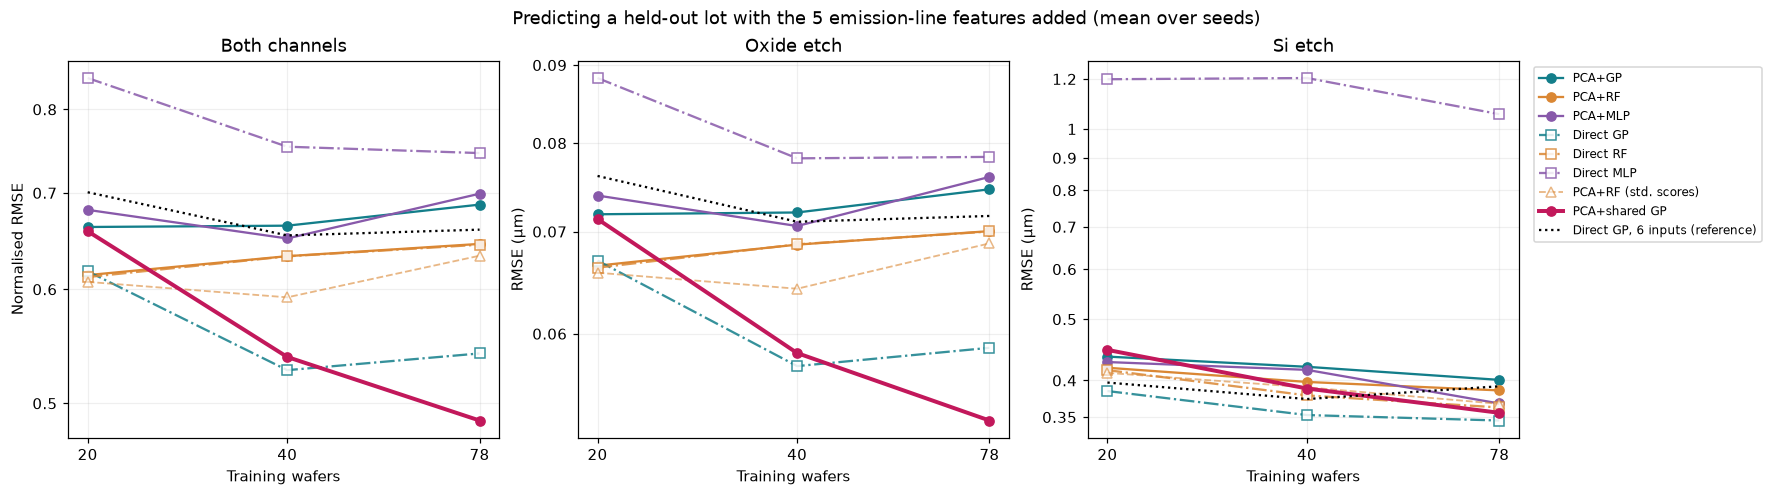

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
colors = {"PCA+GP": "#137e8a", "PCA+RF": "#da8734", "PCA+MLP": "#8859aa", "Direct GP": "#137e8a",
          "Direct RF": "#da8734", "Direct MLP": "#8859aa", "PCA+RF (std. scores)": "#da8734", "PCA+shared GP": "#c2185b"}
best = "+ 5 emission lines"
for ax, (metric, title, ylabel) in zip(axes, [("rmse_norm", "Both channels", "Normalised RMSE"),
                                              ("rmse_oxide_etch", "Oxide etch", "RMSE (µm)"),
                                              ("rmse_si_etch", "Si etch", "RMSE (µm)")]):
    for name in EXTRA_MODELS:
        part = extra_summary[metric].xs(best, level="inputs").xs(name, level="model")
        if name == "PCA+shared GP":
            style = dict(fmt="o-", lw=2.6)
        elif name in MODEL_NAMES:
            style = dict(fmt="o-", lw=1.5)
        elif name in VARIANT_NAMES:
            style = dict(fmt="^--", lw=1.2, alpha=.6, markerfacecolor="white")
        else:
            style = dict(fmt="s-.", lw=1.5, alpha=.85, markerfacecolor="white")
        fmt = style.pop("fmt")
        ax.plot(part.index, part.values, fmt, color=colors[name], label=name, **style)
    ref = extra_summary[metric].xs("6 inputs", level="inputs").xs("Direct GP", level="model")
    ax.plot(ref.index, ref.values, ":", color="black", lw=1.5, label="Direct GP, 6 inputs (reference)")
    ax.set(title=title, xlabel="Training wafers",
           ylabel=ylabel, xscale="log", yscale="log")
    ax.minorticks_off()
    ax.set_xticks(SIZES, labels=SIZES)
    ax.yaxis.set_major_locator(matplotlib.ticker.FixedLocator(
        [0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.35, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.2]))
    ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
    ax.grid(alpha=.2)
axes[2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Predicting a held-out lot with the 5 emission-line features added (mean over seeds)")
save_plot("extra_inputs_curves.png")


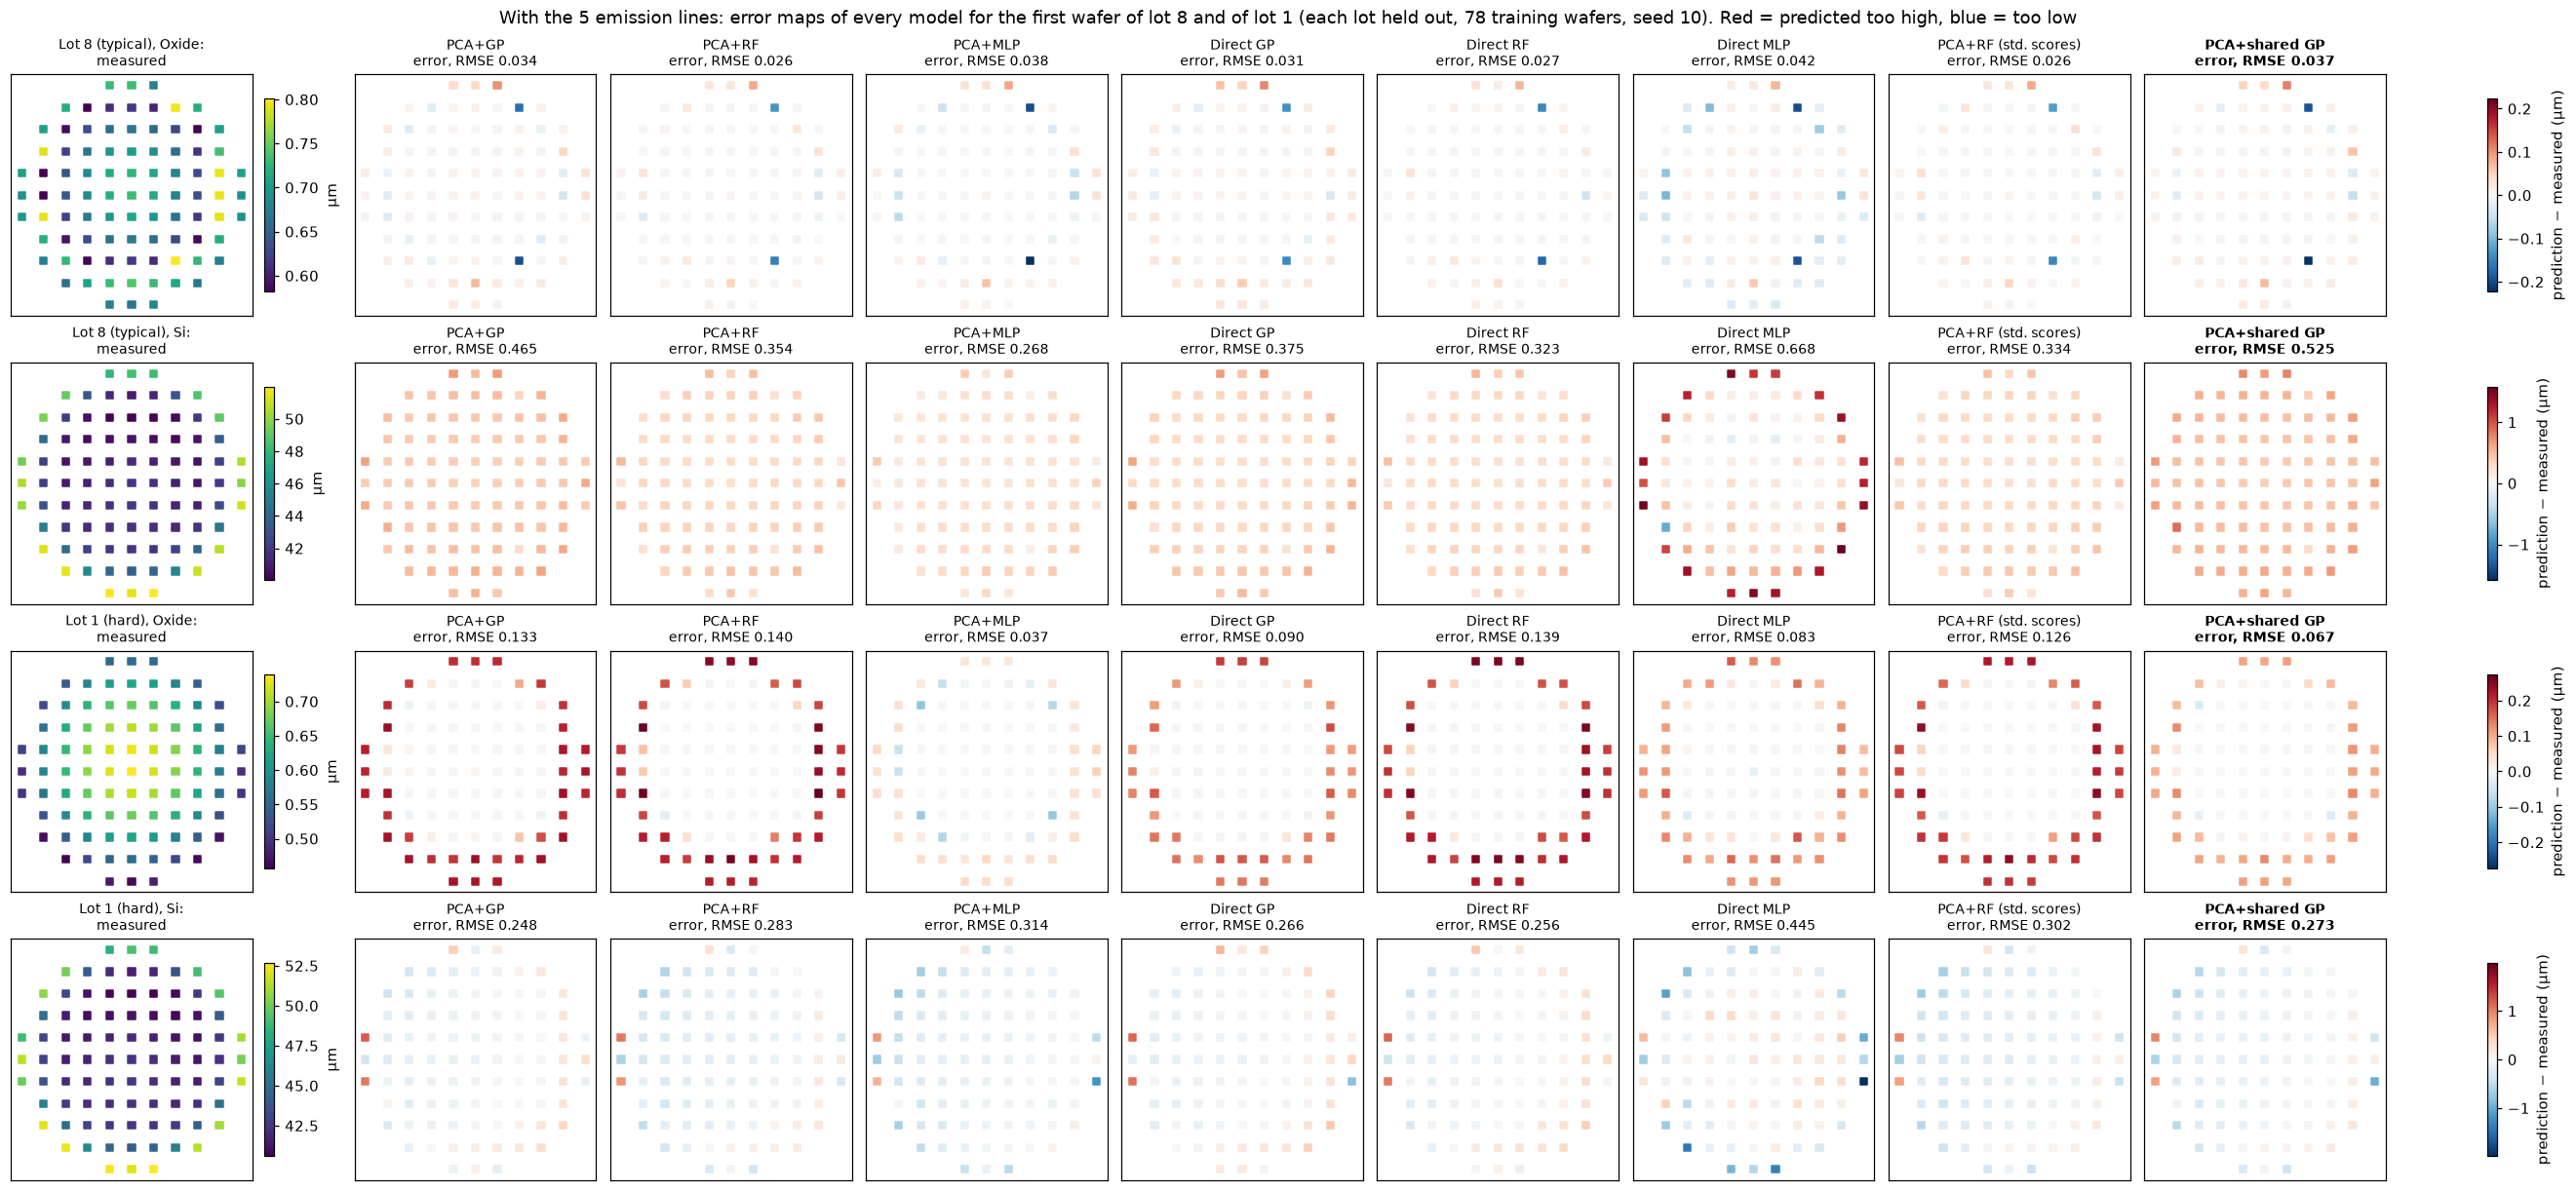

Lot 8 (typical): wafer 2024-08-07_01, measured mean oxide 0.6798 µm, Si 43.744 µm
  PCA+GP                 oxide RMSE 0.0340 µm (mean error +0.0037), Si RMSE 0.4655 µm (mean error +0.460)
  PCA+RF                 oxide RMSE 0.0263 µm (mean error +0.0023), Si RMSE 0.3542 µm (mean error +0.348)
  PCA+MLP                oxide RMSE 0.0377 µm (mean error -0.0030), Si RMSE 0.2675 µm (mean error +0.258)
  Direct GP              oxide RMSE 0.0306 µm (mean error +0.0090), Si RMSE 0.3751 µm (mean error +0.365)
  Direct RF              oxide RMSE 0.0273 µm (mean error +0.0018), Si RMSE 0.3228 µm (mean error +0.316)
  Direct MLP             oxide RMSE 0.0421 µm (mean error -0.0098), Si RMSE 0.6677 µm (mean error +0.449)
  PCA+RF (std. scores)   oxide RMSE 0.0257 µm (mean error +0.0024), Si RMSE 0.3343 µm (mean error +0.328)
  PCA+shared GP          oxide RMSE 0.0374 µm (mean error +0.0044), Si RMSE 0.5245 µm (mean error +0.516)
Lot 1 (hard): wafer 2024-07-02_01, measured mean oxide 0.6018 µm, Si 4

In [20]:
# Example maps for every model with the 5 emission lines: the same two wafers as in the main-run example maps
# (first wafer of lot 8, typical; first wafer of lot 1, hard), each predicted with its lot held out (seed 10, 78 wafers).
# First column: measured map. Other columns: prediction minus measurement for each model, on one colour scale per row.
example_rows = {label: int(np.flatnonzero(lot_of == lot)[0]) for label, lot in EXAMPLES.items()}
panel_rows = [(label, w, c) for label, w in example_rows.items() for c in range(len(CHANNELS))]
fig, axes = plt.subplots(len(panel_rows), 1 + len(EXTRA_MODELS), figsize=(24, 11), constrained_layout=True)
for r, (label, w, c) in enumerate(panel_rows):
    truth = Y_all[w, :, c]
    errors = {name: extra_example_predictions[name][w, :, c] - truth for name in EXTRA_MODELS}
    limit = max(np.abs(e).max() for e in errors.values())
    sc = axes[r, 0].scatter(XY[:, 0], XY[:, 1], c=truth, cmap="viridis", s=22, marker="s")
    axes[r, 0].set_title(f"{label}, {SHORT_LABELS[CHANNELS[c]]}:\nmeasured", fontsize=9)
    fig.colorbar(sc, ax=axes[r, 0], shrink=.8, label="µm")
    for j, name in enumerate(EXTRA_MODELS, start=1):
        err = errors[name]
        sc = axes[r, j].scatter(XY[:, 0], XY[:, 1], c=err, cmap="RdBu_r", vmin=-limit, vmax=limit, s=22, marker="s")
        axes[r, j].set_title(f"{name}\nerror, RMSE {np.sqrt((err**2).mean()):.3f}", fontsize=9,
                             fontweight="bold" if name == "PCA+shared GP" else "normal")
    fig.colorbar(sc, ax=axes[r, 1:], shrink=.8, label="prediction − measured (µm)")
for ax in axes.flat:
    ax.set(aspect="equal", xticks=[], yticks=[])
fig.suptitle(f"With the 5 emission lines: error maps of every model for the first wafer of lot 8 and of lot 1 "
             f"(each lot held out, {max(SIZES)} training wafers, seed {SEEDS[0]}). Red = predicted too high, blue = too low")
save_plot("extra_inputs_example_maps.png")
for label, w in example_rows.items():
    print(f"{label}: wafer {wafers.key[w]}, measured mean oxide {Y_all[w, :, 0].mean():.4f} µm, Si {Y_all[w, :, 1].mean():.3f} µm")
    for name in EXTRA_MODELS:
        err = extra_example_predictions[name][w] - Y_all[w]
        print(f"  {name:22s} oxide RMSE {np.sqrt((err[:, 0]**2).mean()):.4f} µm (mean error {err[:, 0].mean():+.4f}), "
              f"Si RMSE {np.sqrt((err[:, 1]**2).mean()):.4f} µm (mean error {err[:, 1].mean():+.3f})")

In [21]:
# Invariant checks for the extra-inputs section.
assert len(extra_results) == len(EXTRA_SETS) * len(SEEDS) * len(LOTS) * len(SIZES) * len(EXTRA_MODELS)
assert (extra_results.groupby(["inputs", "seed", "n_train", "model"]).n_values.sum() == len(X_all) * POINTS).all()
assert np.isfinite(extra_results[[f"sse_{c}" for c in CHANNELS]]).all().all()
assert all(np.array_equal(X[:, :len(INPUTS)], X_all) for X in EXTRA_SETS.values())   # extra columns are appended
assert set(extra_example_predictions) == set(EXTRA_MODELS)
assert all(not np.isnan(p).any() for p in extra_example_predictions.values())
print("Extra-inputs checks passed. Total fit warnings now:", len(warning_log))


Extra-inputs checks passed. Total fit warnings now: 64140
